# EritroFase · Corrección residual de Zernike con Fourier condicional

Experimento complementario al [notebook del equipo](../EritroFase.ipynb).
Una CNN estima los coeficientes de un campo residual de Fourier de baja frecuencia
sobre un ajuste robusto de Zernike. Se compara con una SIREN por imagen y con una CNN
de salida explícita, todas con el mismo anclaje y pérdida. El piloto y la ablación
usan la partición congelada de 12 recortes de entrenamiento y 5 de validación.
Después de fijar la configuración se evalúan 5 recortes de prueba y 8 de otro día. La letra C identifica la variante de Fourier en este suplemento. El notebook del equipo usa C para su SIREN condicionada.

El experimento usa los 30 PNG de `data/selection/`. El inventario completo,
la curación de recortes y las comprobaciones del código guía se documentan en
las secciones 3 y 4 del notebook del equipo. Aquí se recalculan la corrección y
la evaluación desde los PNG, con salidas en `results/fourier/`.

### Resultado de la corrida registrada

En prueba, Fourier condicional alcanzó **6,468 niveles** de RMS de fondo lento y
**2,91 %** de cambio mediano absoluto de altura. El margen frente a Zernike fue
de 0,019 niveles y mejoró las dos métricas a la vez en 2 de 5 recortes. En los
recortes del día reservado, Zernike dejó ligeramente menos fondo lento.

## 2. Entorno

Ejecute las celdas en orden. Se recalculan las líneas base por defecto. Para
reutilizar las líneas base locales, defina `ERITROFASE_FOURIER_RECALCULAR=0` antes
de iniciar el kernel. El piloto, el entrenamiento y la evaluación del modelo se
ejecutan en cada corrida.

In [1]:
# 2.1 Importaciones y rutas del proyecto
import os
import sys
import json
import time
import random
import platform
from pathlib import Path
from inspect import signature

from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image
import scipy
from scipy import ndimage as ndi
import skimage
from skimage.restoration import unwrap_phase
import torch

# Jupyter puede iniciar en la raíz del proyecto o en la carpeta experiments.
CWD = Path.cwd().resolve()
ROOT = next((p for p in (CWD, *CWD.parents)
             if (p / "data/selection/seleccion.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("No se encontró la raíz con data/selection/seleccion.csv.")

SELECTION_DIR = ROOT / "data" / "selection"
RESULTADOS = ROOT / "results" / "fourier"
FIG_DIR = RESULTADOS / "figures"
TAB_DIR = RESULTADOS / "tables"
RUNS_DIR = RESULTADOS / "runs"
CACHE_DIR = RESULTADOS / "cache"
RECALCULAR = os.environ.get("ERITROFASE_FOURIER_RECALCULAR", "1") != "0"

for carpeta in (FIG_DIR, TAB_DIR, RUNS_DIR, CACHE_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

# El código guía usa importaciones absolutas de módulos vecinos.
sys.path.insert(0, str(ROOT / "reference_code" / "INR"))
import torch.nn as nn
from reliability import compute_reliability_map
from siren import LowFreqBackgroundNetwork, build_coordinate_grid
from unwrapper import compensate_background, compensate_background_zernike

print("Salidas de Fourier:", RESULTADOS)

Salidas de Fourier: S:\dev\GitHub\DeepLearning-Final\results\fourier


In [2]:
SEED = 42

def fijar_semillas(seed: int = SEED) -> None:
    """Fija las semillas de Python, NumPy y PyTorch para que los resultados sean repetibles."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

fijar_semillas(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print("Semilla global:", SEED)

Semilla global: 42


In [3]:
def seleccionar_dispositivo() -> torch.device:
    """Devuelve CUDA si está disponible; si no, MPS (Mac); si no, CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

DEVICE = seleccionar_dispositivo()

def reporte_entorno() -> pd.DataFrame:
    """Tabla con el hardware y las versiones de software usadas en la ejecución."""
    filas = {
        "Sistema operativo": f"{platform.system()} {platform.release()}",
        "Procesador": platform.processor() or platform.machine(),
        "Núcleos lógicos de CPU": os.cpu_count(),
        "Python": sys.version.split()[0],
        "PyTorch": torch.__version__,
        "NumPy": np.__version__,
        "SciPy": scipy.__version__,
        "scikit-image": skimage.__version__,
        "Pandas": pd.__version__,
        "Matplotlib": matplotlib.__version__,
        "Pillow": PIL.__version__,
        "Dispositivo usado": str(DEVICE),
    }
    try:
        import psutil
        filas["RAM total (GB)"] = round(psutil.virtual_memory().total / 1024**3, 1)
    except ImportError:
        filas["RAM total (GB)"] = "no disponible (instale psutil)"
    if DEVICE.type == "cuda":
        props = torch.cuda.get_device_properties(0)
        filas["GPU"] = props.name
        filas["Memoria de la GPU (GB)"] = round(props.total_memory / 1024**3, 1)
        filas["CUDA (versión de PyTorch)"] = torch.version.cuda
    return pd.DataFrame.from_dict(filas, orient="index", columns=["Valor"])

entorno = reporte_entorno()
entorno.to_csv(TAB_DIR / "entorno.csv")
entorno

,Valor
Sistema operativo,Windows 11
Procesador,"AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD"
Núcleos lógicos de CPU,8
Python,3.12.14
PyTorch,2.14.1+cu130
NumPy,2.5.4
SciPy,1.18.1
scikit-image,0.26.0
Pandas,3.1.1
Matplotlib,3.11.2


In [4]:
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "image.cmap": "gray",
})

def guardar_figura(fig, etapa: str, nombre: str) -> None:
    """Guarda una figura ya mostrada en results/fourier/figures/<etapa>/<nombre>.png."""
    carpeta = FIG_DIR / etapa
    carpeta.mkdir(parents=True, exist_ok=True)
    fig.savefig(carpeta / f"{nombre}.png", bbox_inches="tight")

def guardar_tabla(df: pd.DataFrame, nombre: str, index: bool = False) -> None:
    """Guarda una tabla en results/tables/<nombre>.csv."""
    df.to_csv(TAB_DIR / f"{nombre}.csv", index=index)

def barra_color(im, ax, etiqueta: str):
    """Barra de color con la unidad indicada en 'etiqueta'."""
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label(etiqueta)
    return cb

def en_cache(nombre: str, calcular, recalcular: bool = None):
    """Devuelve el resultado guardado en results/fourier/cache/<nombre>.pkl si existe y no se pide recalcular;
    si no, ejecuta calcular(), guarda el resultado y lo devuelve."""
    recalcular = RECALCULAR if recalcular is None else recalcular
    ruta = CACHE_DIR / f"{nombre}.pkl"
    if ruta.exists() and not recalcular:
        print(f"[caché] '{nombre}' cargado de results/fourier/cache/ (no se recalculó)")
        return pd.read_pickle(ruta)
    t0 = time.perf_counter()
    valor = calcular()
    pd.to_pickle(valor, ruta)
    print(f"[calculado] '{nombre}' en {time.perf_counter() - t0:.1f} s y guardado en results/fourier/cache/")
    return valor

## 3. Recortes y preprocesamiento

Se usa la selección versionada de Castañeda et al. (2024). Los cuatro conjuntos
tienen adquisiciones separadas y la generalización corresponde a un día
distinto. Se convierte el gris a fase envuelta bajo la hipótesis del proyecto,
se desenvuelve con semilla fija y se invierte el signo para que las células
queden por encima del fondo. Las magnitudes se expresan en niveles de gris
equivalentes. Las máscaras y el ruido de referencia se calculan a partir de
cada entrada con el ajuste polinomial robusto del protocolo original.

In [5]:
SELECCION = pd.read_csv(SELECTION_DIR / "seleccion.csv")
ORDEN_CONJUNTOS = ["entrenamiento", "validacion", "prueba", "generalizacion"]
tamanos_esperados = [12, 5, 5, 8]
tamanos = SELECCION.conjunto.value_counts().reindex(ORDEN_CONJUNTOS)
assert tamanos.tolist() == tamanos_esperados and len(SELECCION) == sum(tamanos_esperados)
assert SELECCION.archivo.is_unique

IMAGENES = {}
for fila in SELECCION.itertuples():
    with Image.open(SELECTION_DIR / fila.conjunto / fila.archivo) as imagen:
        recorte = np.asarray(imagen, dtype=np.float64)
    assert recorte.shape == (256, 256), fila.archivo
    IMAGENES[fila.archivo] = recorte
conjunto_de = dict(zip(SELECCION.archivo, SELECCION.conjunto))

desarrollo = SELECCION[SELECCION.conjunto != "generalizacion"]
assert desarrollo.ts.is_unique, "Hay dos imágenes de desarrollo de la misma adquisición"
compartidas = [t for t in SELECCION.ts.unique() if SELECCION[SELECCION.ts == t].conjunto.nunique() > 1]
assert not compartidas, f"Adquisiciones compartidas entre conjuntos: {compartidas}"
dias_dev = set(desarrollo.ts.str[:10]); dias_gen = set(SELECCION[SELECCION.conjunto == "generalizacion"].ts.str[:10])
assert dias_dev.isdisjoint(dias_gen)
print(f"Adquisiciones de desarrollo: {desarrollo.ts.nunique()} para {len(desarrollo)} imágenes")
print("Adquisiciones compartidas entre conjuntos: 0")
print(f"Días: desarrollo = {sorted(dias_dev)} | generalización = {sorted(dias_gen)}")
display(SELECCION.groupby("conjunto").agg(
    recortes=("archivo", "size"),
    adquisiciones=("ts", "nunique"),
).reindex(ORDEN_CONJUNTOS))

Adquisiciones de desarrollo: 22 para 22 imágenes
Adquisiciones compartidas entre conjuntos: 0
Días: desarrollo = ['2021-01-29'] | generalización = ['2021-01-28']


,recortes,adquisiciones
conjunto,,
entrenamiento,12,12
validacion,5,5
prueba,5,5
generalizacion,8,3


In [6]:
NG_POR_RAD = 255 / (2 * np.pi)

def gris_a_fase_envuelta(g: np.ndarray) -> np.ndarray:
    """Hipótesis H1.5 (reformulada): gris 0–255 -> fase envuelta en (-π, π]."""
    return 2*np.pi*g/255 - np.pi

SEMILLA_UNWRAP = "rng" if "rng" in signature(unwrap_phase).parameters else "seed"

def desenvolver_fase(fase: np.ndarray) -> np.ndarray:
    """Fija el desempate aleatorio del desenvolvimiento en versiones nuevas y anteriores de scikit-image."""
    return unwrap_phase(fase, **{SEMILLA_UNWRAP: SEED})

def desenvolver(g: np.ndarray) -> np.ndarray:
    """Fase desenvuelta (rad) a partir del gris envuelto (algoritmo de Herráez et al., 2002)."""
    return desenvolver_fase(gris_a_fase_envuelta(g))

H = W = 256
_yy, _xx = np.meshgrid(np.linspace(-1, 1, H), np.linspace(-1, 1, W), indexing="ij")
BASE_POLI = np.stack([np.ones_like(_xx), _xx, _yy, _xx**2, _xx*_yy, _yy**2], -1).reshape(-1, 6)

def ajuste_fondo_robusto(phi: np.ndarray, iteraciones: int = 8, k: float = 2.5):
    """Fondo polinomial de grado 2 por mínimos cuadrados reponderados. Devuelve (fondo, residuo, sigma)."""
    v = phi.ravel(); m = np.ones(v.size, bool)
    for _ in range(iteraciones):
        c = np.linalg.lstsq(BASE_POLI[m], v[m], rcond=None)[0]
        r = v - BASE_POLI @ c
        s = 1.4826 * np.median(np.abs(r[m] - np.median(r[m])))
        m = np.abs(r) < k * s
    return (BASE_POLI @ c).reshape(phi.shape), r.reshape(phi.shape), s

def mascara_celulas(residuo: np.ndarray, sigma: float, signo: int) -> np.ndarray:
    """Células = residuo > 4σ en la dirección 'signo', con apertura morfológica y huecos rellenos."""
    return ndi.binary_fill_holes(ndi.binary_opening(signo * residuo > 4 * sigma, iterations=2))

def preprocesar(g: np.ndarray) -> np.ndarray:
    """Gris envuelto (0–255) -> fase desenvuelta con la célula positiva, en niveles de gris equivalentes."""
    return -desenvolver(g) * NG_POR_RAD

FONDO_FILAS = []
MASCARAS = {}
PREPROCESADAS = {}
for archivo, imagen in IMAGENES.items():
    fase = desenvolver(imagen)
    fondo, residuo, ruido = ajuste_fondo_robusto(fase)
    assert (residuo < -4 * ruido).sum() > (residuo > 4 * ruido).sum(), archivo
    celula = mascara_celulas(residuo, ruido, -1)
    fondo_evaluable = ~ndi.binary_dilation(celula, iterations=6)
    MASCARAS[archivo] = (celula, fondo_evaluable)
    PREPROCESADAS[archivo] = -fase * NG_POR_RAD
    FONDO_FILAS.append({"archivo": archivo, "σ_ruido (niveles eq.)": ruido * NG_POR_RAD})
FONDO = pd.DataFrame(FONDO_FILAS)

## 5–6. Líneas base y criterios de evaluación

Se conservan las definiciones de las secciones 5 y 6 del notebook del equipo.
M1 es el RMS de la componente lenta residual sobre el fondo de referencia.
M2 es la mediana del cambio absoluto relativo de altura de las células
evaluables frente a un anillo local. Se toma la mediana entre recortes.
Los ajustes del fondo se calculan a partir de la imagen. Las máscaras de
referencia se usan para medir la corrección. La fase celular aislada es
desconocida en las imágenes reales.

In [7]:
def dice(a: np.ndarray, b: np.ndarray) -> float:
    return float(2 * (a & b).sum() / (a.sum() + b.sum()))

R_INT, R_EXT, AREA_MIN, SIGMA_SUAVE = 6, 16, 600, 8

def celulas_evaluables(cel: np.ndarray, fon: np.ndarray) -> list:
    """Definición 12: componentes de la máscara de células con área ≥ AREA_MIN, a ≥ R_EXT píxeles del borde y con al menos
    la mitad de su anillo [R_INT, R_EXT] dentro de la región de fondo. Devuelve una lista de pares (célula, anillo)."""
    lab, n = ndi.label(cel)
    salida = []
    for j in range(1, n + 1):
        cj = lab == j
        if cj.sum() < AREA_MIN:
            continue
        ys, xs = np.nonzero(cj)
        if ys.min() < R_EXT or xs.min() < R_EXT or ys.max() >= cel.shape[0] - R_EXT or xs.max() >= cel.shape[1] - R_EXT:
            continue
        ext = ndi.binary_dilation(cj, iterations=R_EXT)
        anillo_completo = ext & ~ndi.binary_dilation(cj, iterations=R_INT)
        anillo = ext & fon
        if anillo.sum() >= 0.5 * anillo_completo.sum():
            salida.append((cj, anillo))
    return salida

def fondo_lento(v: np.ndarray, fon: np.ndarray, sigma: float = SIGMA_SUAVE):
    """Definición 13: promedio gaussiano normalizado de v usando solo píxeles de fondo. Devuelve (mapa, píxeles válidos)."""
    num = ndi.gaussian_filter(np.where(fon, v, 0.0), sigma)
    den = ndi.gaussian_filter(fon.astype(float), sigma)
    valido = fon & (den > 0.5)
    return np.where(valido, num / np.maximum(den, 1e-12), np.nan), valido

def soporte(v: np.ndarray, sigma: float) -> np.ndarray:
    """Definición 15: v > 4σ_ruido, con la misma limpieza morfológica que las máscaras de 3.5."""
    return ndi.binary_fill_holes(ndi.binary_opening(v > 4 * sigma, iterations=2))

def metricas_imagen(v, u, cel, fon, sigma, celulas) -> dict:
    """Métricas de la imagen corregida v frente a la preprocesada u (niveles de gris equivalentes)."""
    lento, valido = fondo_lento(v, fon)
    vb = v[fon]
    dh, corr = [], []
    for cj, rj in celulas:
        h_u = u[cj].mean() - u[rj].mean()
        h_v = v[cj].mean() - v[rj].mean()
        dh.append((h_v - h_u) / h_u)
        corr.append(np.corrcoef(v[cj], u[cj])[0, 1])
    d = dice(soporte(v, sigma), cel)
    return {"RMS lento (niveles eq.)": float(np.sqrt(np.mean(lento[valido] ** 2))),
            "Δh mediana (%)": 100 * float(np.median(dh)) if dh else np.nan,
            "|Δh| mediana (%)": 100 * float(np.median(np.abs(dh))) if dh else np.nan,
            "μ_B": float(vb.mean()), "σ_B": float(vb.std()), "RMS_B/σ_ruido": float(np.sqrt(np.mean(vb ** 2)) / sigma),
            "Dice": d, "IoU": d / (2 - d),
            "correlación mediana": float(np.median(corr)) if corr else np.nan,
            "células evaluadas": len(celulas)}

SIGMA_RUIDO = dict(zip(FONDO.archivo, FONDO["σ_ruido (niveles eq.)"]))
CELULAS_EVAL = {f: celulas_evaluables(*MASCARAS[f]) for f in MASCARAS}     # solo depende de las máscaras de referencia

def metricas_archivo(v: np.ndarray, archivo: str) -> dict:
    """Métricas de una imagen corregida del dataset con su referencia (3.9, 3.10)."""
    cel, fon = MASCARAS[archivo]
    return metricas_imagen(v, PREPROCESADAS[archivo], cel, fon, SIGMA_RUIDO[archivo], CELULAS_EVAL[archivo])

conteo_cel = pd.DataFrame({"conjunto": [conjunto_de[f] for f in CELULAS_EVAL], "células evaluables": [len(c) for c in CELULAS_EVAL.values()]})
print("Células evaluables por imagen (Definición 12):")
display(conteo_cel.groupby("conjunto")["células evaluables"].agg(["sum", "min", "median", "max"]).reindex(ORDEN_CONJUNTOS))

Células evaluables por imagen (Definición 12):


,sum,min,median,max
conjunto,,,,
entrenamiento,32,1,2.5,4
validacion,12,1,3.0,3
prueba,12,2,2.0,3
generalizacion,12,0,1.0,3


In [8]:
import io
import contextlib

def base_polinomial(grado: int) -> np.ndarray:
    """Monomios x^i·y^j con i + j ≤ grado sobre la malla [-1, 1]² de 3.5, como matriz (H·W, n_coeficientes)."""
    columnas = [(_xx ** (t - j)) * (_yy ** j) for t in range(grado + 1) for j in range(t + 1)]
    return np.stack(columnas, -1).reshape(-1, len(columnas))

BASES_POLI = {d: base_polinomial(d) for d in (1, 2, 3)}

def ajuste_polinomial_robusto(u: np.ndarray, grado: int, iteraciones: int = 8, k: float = 2.5) -> np.ndarray:
    """Definición 11: generaliza ajuste_fondo_robusto (3.5) a cualquier grado. Devuelve el fondo estimado."""
    A = BASES_POLI[grado]; v = u.ravel(); m = np.ones(v.size, bool)
    for _ in range(iteraciones):
        c = np.linalg.lstsq(A[m], v[m], rcond=None)[0]
        r = v - A @ c
        s = 1.4826 * np.median(np.abs(r[m] - np.median(r[m])))
        m = np.abs(r) < k * s
    return (A @ c).reshape(u.shape)

def _en_silencio(funcion, *args, **kwargs):
    """Ejecuta una función del código guía sin sus mensajes de progreso (print y tqdm)."""
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        return funcion(*args, **kwargs)

METODOS_LB = ["Pistón", "Polinomio g1", "Polinomio g2", "Polinomio g3", "Zernike (guía)", "SIREN ω0=1 (guía)"]

def _lineas_base_en_imagen(archivo: str) -> dict:
    u = PREPROCESADAS[archivo]
    phi = u / NG_POR_RAD                                     # radianes, como en 4.6
    fondos, tiempos = {}, {}
    def medir(nombre, calcular, extra=0.0):
        t0 = time.perf_counter(); b = calcular()
        tiempos[nombre] = time.perf_counter() - t0 + extra
        fondos[nombre] = np.asarray(b, dtype=np.float32)
    medir("Pistón", lambda: np.full(u.shape, np.median(u)))
    for d in (1, 2, 3):
        medir(f"Polinomio g{d}", lambda d=d: ajuste_polinomial_robusto(u, d))
    t0 = time.perf_counter()
    confiab = compute_reliability_map(torch.tensor(gris_a_fase_envuelta(IMAGENES[archivo]), dtype=torch.float32)).numpy()
    t_conf = time.perf_counter() - t0
    medir("Zernike (guía)", lambda: _en_silencio(compensate_background_zernike, phi, confiab)[1] * NG_POR_RAD, t_conf)
    fijar_semillas(SEED)
    medir("SIREN ω0=1 (guía)", lambda: _en_silencio(compensate_background, phi, confiab)[1] * NG_POR_RAD, t_conf)
    return {"fondos": fondos, "tiempos": tiempos}

ARCHIVOS_LB = SELECCION[SELECCION.conjunto.isin(["entrenamiento", "validacion"])].archivo.tolist()
LINEAS_BASE = {f: en_cache(f"LB_{f[:-4]}", lambda f=f: _lineas_base_en_imagen(f)) for f in ARCHIVOS_LB}
for f in ARCHIVOS_LB:
    assert list(LINEAS_BASE[f]["fondos"]) == METODOS_LB, f"La caché de {f} no tiene los métodos actuales"
    assert np.isclose(float(LINEAS_BASE[f]["fondos"]["Pistón"].flat[0]), float(np.median(PREPROCESADAS[f])), atol=1e-3), \
        f"La caché de {f} no corresponde a los datos actuales"
print(f"Líneas base disponibles para {len(ARCHIVOS_LB)} imágenes "
      f"({(SELECCION.conjunto == 'entrenamiento').sum()} de entrenamiento y {(SELECCION.conjunto == 'validacion').sum()} de validación).")

[calculado] 'LB_Image__2021-01-29__12-29-32_4-11' en 10.2 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-29__12-59-27_2-4' en 2.4 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-29__13-01-44_4-16' en 2.6 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-29__13-04-29_1-7' en 2.2 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-29__13-13-16_2-15' en 2.7 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-29__13-23-48_2-12' en 2.5 s y guardado en results/fourier/cache/


... (7 outputs left out)

[calculado] 'LB_Image__2021-01-29__13-01-51_2-8' en 2.6 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-29__13-05-53_3-6' en 2.5 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-29__13-11-36_1-12' en 2.3 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-29__13-26-28_4-11' en 2.5 s y guardado en results/fourier/cache/
Líneas base disponibles para 17 imágenes (12 de entrenamiento y 5 de validación).


In [9]:
ARCHIVOS_VAL = SELECCION[SELECCION.conjunto == "validacion"].archivo.tolist()
EVAL_LB_VAL = pd.DataFrame([{"archivo": f[7:-4], "método": m,
                             **metricas_archivo(PREPROCESADAS[f] - LINEAS_BASE[f]["fondos"][m], f)}
                            for f in ARCHIVOS_VAL for m in METODOS_LB])
guardar_tabla(EVAL_LB_VAL, "LB_metricas_validacion_por_imagen")
L, DH, ADH = "RMS lento (niveles eq.)", "Δh mediana (%)", "|Δh| mediana (%)"
COLS_M = [L, DH, ADH, "μ_B", "σ_B", "RMS_B/σ_ruido", "Dice", "IoU", "correlación mediana"]
RESUMEN_LB_VAL = EVAL_LB_VAL.groupby("método")[COLS_M].median().loc[METODOS_LB]
RESUMEN_LB_VAL.insert(0, "comparte ajuste con la referencia", [m in ("Polinomio g2", "Polinomio g3") for m in METODOS_LB])
guardar_tabla(RESUMEN_LB_VAL, "LB_metricas_validacion", index=True)
print("Mediana sobre las 5 imágenes de validación:")
display(RESUMEN_LB_VAL.round(2))
print("Por imagen — RMS del fondo lento (niveles eq.):")
display(EVAL_LB_VAL.pivot(index="archivo", columns="método", values=L)[METODOS_LB].round(1))
print("Por imagen — Δh mediana (%) y número de células evaluadas:")
tabla_dh = EVAL_LB_VAL.pivot(index="archivo", columns="método", values=DH)[METODOS_LB].round(1)
tabla_dh["células evaluadas"] = EVAL_LB_VAL.groupby("archivo")["células evaluadas"].first()
display(tabla_dh)

r = RESUMEN_LB_VAL
H6_1 = bool(r.loc["Zernike (guía)", ADH] < 5)
H6_2 = bool(r.loc["SIREN ω0=1 (guía)", DH] < -10)
H6_3 = bool(r.loc["SIREN ω0=1 (guía)", L] < r.loc["Zernike (guía)", L])
for nombre, valor in (("H6.1", H6_1), ("H6.2", H6_2), ("H6.3", H6_3)):
    print(nombre + ":", "SE CUMPLE" if valor else "SE RECHAZA")

grados = ["Polinomio g1", "Polinomio g2", "Polinomio g3"]
mejor_lento = r.loc[grados, L].min()
aptos = [m for m in grados if r.loc[m, ADH] < 5 and r.loc[m, L] <= mejor_lento + 2]
GRADO_LB = aptos[0] if aptos else r.loc[grados, L].idxmin()
print(f"Grados aptos: {aptos}  →  línea base polinomial elegida: {GRADO_LB}")

Mediana sobre las 5 imágenes de validación:

,comparte ajuste con la referencia,RMS lento (niveles eq.),Δh mediana (%),|Δh| mediana (%),μ_B,σ_B,RMS_B/σ_ruido,Dice,IoU,correlación mediana
método,,,,,,,,,,
Pistón,False,22.63,0.00,0.00,-10.70,22.02,1.39,0.97,0.94,1.00
Polinomio g1,False,15.80,-0.01,0.26,-2.47,17.42,1.12,0.97,0.95,1.00
Polinomio g2,True,12.81,-0.22,0.98,-2.17,15.26,0.96,1.00,1.00,1.00
Polinomio g3,True,7.90,-1.14,1.37,-1.33,10.84,0.81,0.98,0.96,0.99
Zernike (guía),False,6.39,-2.55,2.55,0.42,9.71,0.75,0.97,0.95,0.99
SIREN ω0=1 (guía),False,3.45,-12.76,12.76,0.71,6.70,0.46,0.96,0.92,0.98


Por imagen — RMS del fondo lento (niveles eq.):


método,Pistón,Polinomio g1,Polinomio g2,Polinomio g3,Zernike (guía),SIREN ω0=1 (guía)
archivo,,,,,,
2021-01-29__12-33-19_3-8,27.4,15.8,12.8,12.8,10.9,4.3
2021-01-29__13-01-51_2-8,22.6,16.4,13.1,10.2,8.7,4.0
2021-01-29__13-05-53_3-6,13.8,11.7,8.5,6.2,5.1,3.3
2021-01-29__13-11-36_1-12,29.9,15.9,25.0,7.9,5.7,3.5
2021-01-29__13-26-28_4-11,17.6,12.1,10.6,7.8,6.4,3.4


Por imagen — Δh mediana (%) y número de células evaluadas:


método,Pistón,Polinomio g1,Polinomio g2,Polinomio g3,Zernike (guía),SIREN ω0=1 (guía),células evaluadas
archivo,,,,,,,
2021-01-29__12-33-19_3-8,0.0,0.2,-0.2,-0.2,-2.6,-26.6,3
2021-01-29__13-01-51_2-8,0.0,-0.2,-1.0,-1.1,-2.6,-9.1,3
2021-01-29__13-05-53_3-6,0.0,0.0,0.0,-1.0,-1.1,-9.4,2
2021-01-29__13-11-36_1-12,-0.0,-0.3,3.3,-2.5,-4.6,-12.8,1
2021-01-29__13-26-28_4-11,0.0,-0.0,-1.0,-1.8,-1.6,-14.8,3


H6.1: SE CUMPLE
H6.2: SE CUMPLE
H6.3: SE CUMPLE
Grados aptos: ['Polinomio g3']  →  línea base polinomial elegida: Polinomio g3


### 6.5 Criterio de éxito del modelo (fijado antes de entrenarlo)

Se evalúa en el conjunto de prueba (sección 9) con las métricas principales M1 y M2:
1. **Preservación:** $\lvert\Delta h\rvert$ mediana ≤ 5 %, la cota del cambio legítimo por curvatura (6.1).
2. **Fondo:** RMS lento mediano menor o igual que el de la mejor línea base que cumpla la condición 1, entre L0, L1 con el grado elegido en 6.4, L2 y L3.
3. **Consistencia:** se reporta en cuántas de las 5 imágenes de prueba el modelo supera a esa línea base en las dos métricas a la vez.

Con 5 imágenes, un resultado favorable se describirá como "consistente con una mejora" y no como una mejora demostrada. Este criterio puede ajustarse con el grupo **antes** de entrenar, nunca después de mirar prueba.

### 6.6 Contraste de las hipótesis de la sección 6

## 7. Arquitectura del modelo *(lineamiento B · etapa E3)*

Se estima el fondo $b$ en la fase desenvuelta $u = b + c + \varepsilon$. Las tres variantes parten del ajuste robusto de Zernike $b_0$ de la línea base L2 y aprenden una corrección suave $\delta_\theta$ para obtener $\hat b = b_0 + \delta_\theta$. Compartir $b_0$, la pérdida y el conjunto de validación permite evaluar la parametrización y el esquema de ajuste. Como estas variantes cambian ambos aspectos, el piloto compara estrategias completas.

### 7.1 Alternativas y criterio de selección

| Variante | Entrada a la red | Representación de la corrección | Ajuste |
|---|---|---|---|
| A · SIREN por imagen | Coordenadas $(x,y)$ | SIREN compacta con dos capas ocultas tras la entrada | Una red nueva por imagen |
| B · CNN compartida | Residuo de Zernike y pesos suaves | Mapa convolucional de $16\times16$, interpolado | Una red sobre las 12 imágenes de entrenamiento |
| C · Fourier condicional | Residuo de Zernike y pesos suaves | Una CNN predice coeficientes de senos y cosenos en coordenadas | Una red sobre las 12 imágenes de entrenamiento |

**H7.1.** Al menos una variante con representación implícita mejora en validación el RMS lento de Zernike con una mediana de $|\Delta h|\le 5\,\%$. Se comparan las tres variantes con semilla 42 y hasta 120 actualizaciones de Adam por ajuste. A y C son elegibles por el objetivo de usar una representación implícita. Entre las elegibles que preserven la altura se escoge la de menor RMS lento mediano. Si ninguna cumple la cota, se escoge la que menor alteración tenga, con el RMS lento como desempate. B cuantifica el desempeño de una red compartida con una salida espacial explícita. La fase de prueba queda fuera del piloto.

In [10]:
# 7.1 Datos de la red, arquitecturas y pérdida común
import torch.nn.functional as F

NODO_FONDO = 64
COORDENADAS_FONDO = build_coordinate_grid(NODO_FONDO, NODO_FONDO, device=DEVICE)
# Pares conjugados representan la misma frecuencia real; se conserva uno.
FRECUENCIAS = [(kx, ky) for kx in range(3) for ky in range(-2, 3)
               if (kx > 0 or ky > 0) and kx**2 + ky**2 <= 5]
ANGULOS = torch.pi * COORDENADAS_FONDO @ torch.tensor(FRECUENCIAS, dtype=torch.float32, device=DEVICE).T
BASE_FOURIER = torch.cat([torch.ones_like(ANGULOS[:, :1]), ANGULOS.sin(), ANGULOS.cos()], dim=1)


class CNNFondo(nn.Module):
    """B produce una malla gruesa; C produce los coeficientes del campo continuo."""
    def __init__(self, metodo):
        super().__init__()
        self.metodo = metodo
        self.encoder = nn.Sequential(
            nn.Conv2d(2, 16, 5, stride=2, padding=2), nn.SiLU(),
            nn.Conv2d(16, 24, 3, stride=2, padding=1), nn.SiLU(),
        )
        if metodo == "B":
            self.cabeza = nn.Conv2d(24, 1, 3, padding=1)
            salida = self.cabeza
        else:
            salida = nn.Linear(32, BASE_FOURIER.shape[1])
            self.cabeza = nn.Sequential(
                nn.Conv2d(24, 16, 3, stride=2, padding=1), nn.SiLU(),
                nn.Flatten(), nn.Linear(16 * 8 * 8, 32), nn.SiLU(), salida,
            )
        nn.init.zeros_(salida.weight)
        nn.init.zeros_(salida.bias)

    def forward(self, entrada):
        prediccion = self.cabeza(self.encoder(entrada))
        if self.metodo == "B":
            return F.interpolate(prediccion, size=(NODO_FONDO, NODO_FONDO),
                                 mode="bicubic", align_corners=True)
        return (prediccion @ BASE_FOURIER.T).reshape(-1, 1, NODO_FONDO, NODO_FONDO)


def crear_modelo_fondo(metodo, semilla):
    fijar_semillas(semilla)
    if metodo == "A":
        modelo = LowFreqBackgroundNetwork(hidden_dim=32, n_layers=2, omega_0=4.0)
        nn.init.zeros_(modelo.output.weight)
        nn.init.zeros_(modelo.output.bias)
    else:
        modelo = CNNFondo(metodo)
    return modelo.to(DEVICE)


def preparar_entrada_fondo(u, b0):
    """Construye datos del ajuste sin máscaras ni estimaciones de ruido de referencia."""
    residuo = np.asarray(u - b0, dtype=np.float32)
    diferencias = np.r_[np.diff(u, axis=0).ravel(), np.diff(u, axis=1).ravel()]
    escala = max(1.0, float(1.4826 * np.median(np.abs(diferencias - np.median(diferencias))) / np.sqrt(2)))
    residuo = residuo / escala
    lento = ndi.gaussian_filter(residuo, 2.0)
    # Una zona elevada respecto a Zernike es compatible con célula. Las caídas
    # extremas también se reducen por posibles errores del desenvolvimiento.
    pesos = 1 / (1 + (np.maximum(lento, 0) / 2.5)**4 + (np.minimum(lento, 0) / 4)**4)
    tensor = torch.from_numpy(np.stack([residuo * pesos, pesos]).astype(np.float32))[None].to(DEVICE)
    datos = F.adaptive_avg_pool2d(tensor, (NODO_FONDO, NODO_FONDO))
    ponderacion = datos[:, 1:]
    objetivo = datos[:, :1] / ponderacion.clamp_min(1e-6)
    entrada = torch.cat([objetivo.clamp(-4, 4), ponderacion], dim=1)
    return (entrada, objetivo, ponderacion), escala


def delta_fondo(modelo, metodo, entrada):
    if metodo == "A":
        return modelo(COORDENADAS_FONDO).reshape(1, 1, NODO_FONDO, NODO_FONDO)
    return modelo(entrada)


def perdida_fondo(delta, objetivo, pesos, config):
    residuo = objetivo - delta
    denominador = pesos.sum().clamp_min(1e-6)
    ajuste = (pesos * (torch.sqrt(residuo.square() + 0.1**2) - 0.1)).sum() / denominador
    signo = (pesos * F.relu(-residuo - 0.75).square()).sum() / denominador
    dxx = delta[..., 4:] - 2 * delta[..., 2:-2] + delta[..., :-4]
    dyy = delta[..., 4:, :] - 2 * delta[..., 2:-2, :] + delta[..., :-4, :]
    curvatura = dxx.square().mean() + dyy.square().mean()
    return ajuste + config["signo"] * signo + config["curvatura"] * curvatura + 0.01 * delta.square().mean()


def sincronizar_fondo():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps":
        torch.mps.synchronize()


def expandir_fondo(delta, escala, b0):
    with torch.no_grad():
        delta_grande = F.interpolate(delta, size=b0.shape, mode="bicubic", align_corners=True)
    return b0 + escala * delta_grande[0, 0].detach().cpu().numpy()


def adaptar_siren(datos, config):
    modelo = crear_modelo_fondo("A", config["semilla"])
    entrada, objetivo, pesos = datos
    optimizador = torch.optim.Adam(modelo.parameters(), lr=config["lr"])
    historial = []
    for paso in range(config["pasos"]):
        optimizador.zero_grad(set_to_none=True)
        perdida = perdida_fondo(delta_fondo(modelo, "A", entrada), objetivo, pesos, config)
        perdida.backward()
        optimizador.step()
        if paso % 10 == 0 or paso + 1 == config["pasos"]:
            historial.append((paso, perdida.detach()))
    with torch.no_grad():
        delta = delta_fondo(modelo, "A", entrada)
        historial.append((config["pasos"], perdida_fondo(delta, objetivo, pesos, config)))
    # Los pasos 0..N-1 registran el estado anterior a la actualización correspondiente.
    return delta, [(paso, valor.item()) for paso, valor in historial]


def entrenar_compartido(datos_ent, datos_val, config):
    metodo = config["metodo"]
    modelo = crear_modelo_fondo(metodo, config["semilla"])
    optimizador = torch.optim.Adam(modelo.parameters(), lr=config["lr"])
    train = tuple(torch.cat(campos) for campos in zip(*datos_ent))
    val = tuple(torch.cat(campos) for campos in zip(*datos_val))
    rng = np.random.default_rng(config["semilla"])
    historial = []
    paso = 0
    for epoca in range(config["epocas"] + 1):
        modelo.eval()
        with torch.no_grad():
            loss_ent = perdida_fondo(modelo(train[0]), *train[1:], config)
            loss_val = perdida_fondo(modelo(val[0]), *val[1:], config)
        historial.extend([(paso, "entrenamiento", loss_ent.item()), (paso, "validacion", loss_val.item())])
        if epoca == config["epocas"]:
            break
        modelo.train()
        for lote in np.array_split(rng.permutation(len(datos_ent)), 3):
            indices = torch.as_tensor(lote, device=DEVICE)
            entrada, objetivo, pesos = (tensor[indices] for tensor in train)
            optimizador.zero_grad(set_to_none=True)
            perdida = perdida_fondo(modelo(entrada), objetivo, pesos, config)
            perdida.backward()
            optimizador.step()
            paso += 1
    return modelo.eval(), historial

### 7.2 Diagrama y dimensiones

```text
u (256×256) ──► ajuste robusto de Zernike ──► b₀ (256×256)
       │                                       │
       └──────────► u − b₀, peso suave ◄────────┘
                             │
                    datos 2 × 64 × 64
                             │
     A: SIREN(x,y)     B: CNN → malla     C: CNN → coeficientes
             └───────────────┼──────────────────────┘
                        δ (64×64)
                             │ bicúbica y cambio de escala
                             ▼
                   b̂ = b₀ + δ (256×256)
                             │
                             ▼
                       v = u − b̂
```

En A, las coordenadas alimentan capas sinusoidales de ancho 32 ($\omega_0=4$). Se reutiliza la clase SIREN de la guía con una salida inicial de cero. En C, cada coeficiente multiplica un seno o coseno de la base fija $\pi(k_xx+k_yy)$, con $k_x^2+k_y^2\le 5$. La cabeza incluye un término constante. Ambas parametrizaciones se consultan sobre una malla de $64\times64$ para ajustar y luego se interpolan a la resolución del recorte. B usa la misma malla de cálculo, generada desde una salida convolucional de $16\times16$.

La pérdida es autosupervisada. Un peso suave calculado a partir de $u-b_0$ reduce la influencia de regiones muy positivas, compatibles con células, y de residuos negativos extremos. Se agregan observaciones en bloques de $4\times4$ con estos pesos. Se combina Charbonnier ponderada con una penalización de signo por debajo de $-0{,}75$ unidades normalizadas, segundas diferencias de la corrección de Zernike, con separación de dos nodos y una penalización cuadrática débil de su amplitud. La escala es el MAD de diferencias vecinas multiplicado por $1{,}4826/\sqrt{2}$, con mínimo de un nivel. La corrección y sus penalizaciones se expresan en esa escala. Las máscaras de referencia intervienen al medir M1–M4, y la selección de variantes usa M1 y M2 en validación.

Si $t$ es la media ponderada de la observación en un bloque, $w$ su peso y $e=t-\delta_\theta$, el ajuste minimiza
$$
\mathcal L=
\left\langle\sqrt{e^2+0{,}1^2}-0{,}1\right\rangle_w
+\lambda_g\left\langle[-e-0{,}75]_+^2\right\rangle_w
+\lambda_s\left(\overline{(D_x^2\delta_\theta)^2}+\overline{(D_y^2\delta_\theta)^2}\right)
+0{,}01\,\overline{\delta_\theta^2}.
$$
Los corchetes angulares indican promedio ponderado y la barra indica promedio uniforme.


In [11]:
# 7.2 Piloto. Aquí se cargan únicamente los datos de entrenamiento y validación.
ARCHIVOS_ENT = SELECCION.loc[SELECCION.conjunto == "entrenamiento", "archivo"].tolist()
NOMBRE_ZERNIKE = "Zernike (guía)"
DATOS_DESARROLLO = {
    f: preparar_entrada_fondo(PREPROCESADAS[f], LINEAS_BASE[f]["fondos"][NOMBRE_ZERNIKE])
    for f in ARCHIVOS_ENT + ARCHIVOS_VAL
}
CONFIG_PILOTO = {"semilla": SEED, "pasos": 120, "epocas": 40, "lr": 0.003,
                 "signo": 0.15, "curvatura": 25.0}
PARAMETROS_FONDO = {m: sum(p.numel() for p in crear_modelo_fondo(m, SEED).parameters())
                    for m in ("A", "B", "C")}


def correr_desarrollo(config, incluir_entrenamiento=False):
    metodo = config["metodo"]
    sincronizar_fondo()
    inicio = time.perf_counter()
    if metodo == "A":
        modelo, historial = None, []
    else:
        modelo, historial = entrenar_compartido(
            [DATOS_DESARROLLO[f][0] for f in ARCHIVOS_ENT],
            [DATOS_DESARROLLO[f][0] for f in ARCHIVOS_VAL], config,
        )
    fondos = {}
    archivos = ARCHIVOS_VAL + (ARCHIVOS_ENT if incluir_entrenamiento and metodo == "A" else [])
    for archivo in archivos:
        datos, escala = DATOS_DESARROLLO[archivo]
        b0 = LINEAS_BASE[archivo]["fondos"][NOMBRE_ZERNIKE]
        if metodo == "A":
            delta, curva = adaptar_siren(datos, config)
            historial.extend((paso, conjunto_de[archivo], valor) for paso, valor in curva)
        else:
            with torch.no_grad():
                delta = modelo(datos[0])
        fondos[archivo] = expandir_fondo(delta, escala, b0)
    sincronizar_fondo()
    tiempo = time.perf_counter() - inicio
    detalle = pd.DataFrame([
        {"archivo": f, **metricas_archivo(PREPROCESADAS[f] - fondos[f], f)} for f in ARCHIVOS_VAL
    ])
    assert np.isfinite(detalle[L]).all() and detalle[ADH].notna().all()
    curva = pd.DataFrame(historial, columns=["actualizaciones", "conjunto", "pérdida"])
    return modelo, detalle, curva, tiempo


def ordenar_validacion(tabla):
    """Preservación primero; fondo si hay variantes aptas; orden estable ante empate."""
    aptas = tabla[tabla[ADH] <= 5]
    return (tabla.sort_values([ADH, L], kind="stable") if aptas.empty
            else aptas.sort_values([L, ADH], kind="stable"))


piloto = []
for metodo in ("A", "B", "C"):
    _, detalle, _, segundos = correr_desarrollo({**CONFIG_PILOTO, "metodo": metodo})
    piloto.append({"variante": metodo, L: detalle[L].median(), ADH: detalle[ADH].median(),
                   "parámetros": PARAMETROS_FONDO[metodo], "ajuste y predicción (s)": segundos})
PILOTO = pd.DataFrame(piloto).set_index("variante")
VARIANTE_ELEGIDA = ordenar_validacion(PILOTO.loc[["A", "C"]]).index[0]
aptas_piloto = PILOTO.loc[["A", "C"]]
H7_1 = bool(((aptas_piloto[ADH] <= 5) & (aptas_piloto[L] < RESUMEN_LB_VAL.loc[NOMBRE_ZERNIKE, L])).any())
guardar_tabla(PILOTO, "E3_piloto_validacion", index=True)
display(PILOTO.round(3))
print(f"H7.1: {'SE CUMPLE' if H7_1 else 'NO SE CUMPLE'}. Variante elegida: {VARIANTE_ELEGIDA}.")

,RMS lento (niveles eq.),|Δh| mediana (%),parámetros,ajuste y predicción (s)
variante,,,,
A,6.759,2.636,2241,1.682
B,6.753,2.565,4513,0.494
C,6.738,2.597,41261,0.385


H7.1: NO SE CUMPLE. Variante elegida: C.


**Lectura del piloto.** Las tres variantes preservaron la altura dentro del 5 %. C obtuvo 6,738 niveles de RMS lento frente a 6,759 de A. Esa diferencia proviene de una sola semilla. Zernike quedó en 6,388 niveles, por lo que se rechaza H7.1. Los presupuestos igualan actualizaciones por ajuste. A ejecuta ese número por recorte y B y C lo ejecutan una vez sobre el conjunto de entrenamiento.

## 8. Entrenamiento y configuración experimental *(lineamientos B y C · etapa E4)*

Se aumenta el presupuesto a 240 actualizaciones por ajuste y se estudia la sensibilidad a la curvatura y al signo solo en validación. Se prueban dos semillas por configuración. Cada fila de selección resume la mediana de las dos medianas por imagen. Se usa la misma regla de preservación y RMS que en el piloto. Se fija la semilla 42 para el ajuste que se usará en prueba y generalización.

### 8.1 Hiperparámetros, pérdida y ablación

Se usa Adam con paso 0,003. B y C usan lotes de 4 recortes, 3 actualizaciones por época y un barajado reproducible. A usa todas las observaciones ponderadas de un recorte en cada actualización. Se comparan tres pesos de curvatura (5, 25 y 100) con peso de signo 0,15. La ablación elimina el término de signo y deja la curvatura en 25. **H8.1.** A curvatura fija, el signo disminuye el cambio mediano absoluto de altura celular sin elevar el RMS lento de validación en más de 1 nivel. El ejercicio estima sensibilidad a la inicialización con dos semillas y a un solo conjunto de validación.

In [12]:
# 8.1 Presupuesto y variantes congelados antes de evaluar prueba
CONFIG_DESARROLLO = {**CONFIG_PILOTO, "metodo": VARIANTE_ELEGIDA, "pasos": 240, "epocas": 80}
AJUSTES_FISICOS = {
    "curvatura 25": {"curvatura": 25.0, "signo": 0.15},
    "curvatura 5": {"curvatura": 5.0, "signo": 0.15},
    "curvatura 100": {"curvatura": 100.0, "signo": 0.15},
    "sin signo": {"curvatura": 25.0, "signo": 0.0},
}
SEMILLAS_FONDO = (SEED, 1729)
CARPETA_CORRIDA = RUNS_DIR / "eritrofase_final"
CARPETA_CORRIDA.mkdir(parents=True, exist_ok=True)

### 8.2 Ajuste, validación y registro de la corrida

In [13]:
# 8.2 Selección exclusivamente con las imágenes de validación
evaluaciones, metricas_validacion = [], []
for nombre, ajuste in AJUSTES_FISICOS.items():
    for semilla in SEMILLAS_FONDO:
        config = {**CONFIG_DESARROLLO, **ajuste, "semilla": semilla}
        _, detalle, _, segundos = correr_desarrollo(config)
        evaluaciones.append({"ajuste": nombre, "semilla": semilla, L: detalle[L].median(),
                             ADH: detalle[ADH].median(), "ajuste y predicción (s)": segundos})
        metricas_validacion.append(detalle.assign(ajuste=nombre, semilla=semilla))
EVAL_AJUSTES = pd.DataFrame(evaluaciones)
RESUMEN_AJUSTES = EVAL_AJUSTES.groupby("ajuste", sort=False)[[L, ADH]].median()
AJUSTE_ELEGIDO = ordenar_validacion(RESUMEN_AJUSTES).index[0]
CONFIG_ELEGIDA = {**CONFIG_DESARROLLO, **AJUSTES_FISICOS[AJUSTE_ELEGIDO]}
MODELO_ELEGIDO, VALIDACION_FINAL, CURVAS_FONDO, SEGUNDOS_DESARROLLO = correr_desarrollo(
    CONFIG_ELEGIDA, incluir_entrenamiento=True
)
assert np.allclose(
    VALIDACION_FINAL[[L, ADH]].median().to_numpy(),
    EVAL_AJUSTES.loc[(EVAL_AJUSTES.ajuste == AJUSTE_ELEGIDO) & (EVAL_AJUSTES.semilla == SEED), [L, ADH]].iloc[0],
    rtol=1e-4,
)
H8_1 = bool(RESUMEN_AJUSTES.loc["curvatura 25", ADH] < RESUMEN_AJUSTES.loc["sin signo", ADH]
            and RESUMEN_AJUSTES.loc["curvatura 25", L] <= RESUMEN_AJUSTES.loc["sin signo", L] + 1)
if MODELO_ELEGIDO is not None:
    torch.save(MODELO_ELEGIDO.state_dict(), CARPETA_CORRIDA / "pesos.pt")

registro = {
    "config_elegida": CONFIG_ELEGIDA, "ajuste_elegido": AJUSTE_ELEGIDO,
    "alternativas_piloto": CONFIG_PILOTO, "ajustes_fisicos": AJUSTES_FISICOS,
    "semillas": list(SEMILLAS_FONDO), "archivos_entrenamiento": ARCHIVOS_ENT,
    "archivos_validacion": ARCHIVOS_VAL, "dispositivo": str(DEVICE), "pytorch": str(torch.__version__),
    "malla": NODO_FONDO, "parametros": PARAMETROS_FONDO[VARIANTE_ELEGIDA],
    "segundos_ajuste_y_prediccion_desarrollo": SEGUNDOS_DESARROLLO,
}
(CARPETA_CORRIDA / "config.json").write_text(json.dumps(registro, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
pd.concat(metricas_validacion, ignore_index=True).to_csv(CARPETA_CORRIDA / "validacion_por_imagen.csv", index=False)
EVAL_AJUSTES.to_csv(CARPETA_CORRIDA / "validacion_por_semilla.csv", index=False)
CURVAS_FONDO.to_csv(CARPETA_CORRIDA / "curvas.csv", index=False)
guardar_tabla(RESUMEN_AJUSTES, "E4_ablacion_validacion", index=True)
display(RESUMEN_AJUSTES.round(3))
display(EVAL_AJUSTES.round(3))
print(f"Ajuste elegido: {AJUSTE_ELEGIDO}. H8.1: {'SE CUMPLE' if H8_1 else 'NO SE CUMPLE'}.")

,RMS lento (niveles eq.),|Δh| mediana (%)
ajuste,,
curvatura 25,6.735,2.619
curvatura 5,6.693,2.654
curvatura 100,6.779,2.581
sin signo,6.585,2.591


,ajuste,semilla,RMS lento (niveles eq.),|Δh| mediana (%),ajuste y predicción (s)
0,curvatura 25,42,6.696,2.617,0.737
1,curvatura 25,1729,6.773,2.622,0.721
2,curvatura 5,42,6.628,2.629,0.728
3,curvatura 5,1729,6.757,2.680,0.724
4,curvatura 100,42,6.736,2.567,0.696
5,curvatura 100,1729,6.821,2.595,0.714
6,sin signo,42,6.568,2.597,0.761
7,sin signo,1729,6.602,2.586,0.750


Ajuste elegido: sin signo. H8.1: NO SE CUMPLE.


### 8.3 Curvas de ajuste y validación

Para A, las curvas son medianas de ajustes independientes en cada conjunto. Una brecha entre ellas refleja diferencias de dificultad o calidad de los recortes. El riesgo de absorber la señal celular se evalúa comparando M1 y M2 con las líneas base. Para B y C, las curvas comparan el ajuste sobre los datos usados por el optimizador y sobre imágenes de validación sin actualización de pesos. Se conserva el presupuesto completo en ambas semillas. Se incluye el punto inicial, que corresponde al ajuste de Zernike.

**Lectura de la ablación.** Con curvatura 25, quitar el término de signo redujo el RMS lento de 6,735 a 6,585 niveles y el cambio de altura de 2,62 % a 2,59 %. Se rechaza H8.1. La configuración elegida preservó la altura con ambas semillas y dio 6,568 y 6,602 niveles de RMS en validación. El ajuste conserva la ponderación de observaciones, la pérdida robusta y la penalización de curvatura.


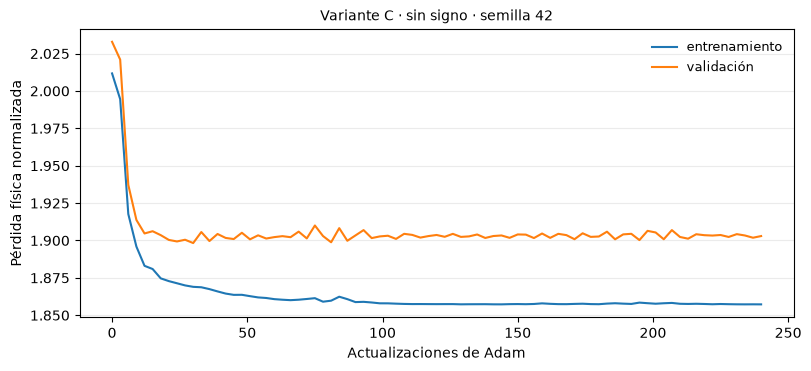

In [14]:
# 8.3 Curvas de la configuración elegida
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
for conjunto, color in (("entrenamiento", "tab:blue"), ("validacion", "tab:orange")):
    curva = CURVAS_FONDO.loc[CURVAS_FONDO.conjunto == conjunto]
    mediana = curva.groupby("actualizaciones")["pérdida"].median()
    ax.plot(mediana.index, mediana, color=color, label=conjunto.replace("validacion", "validación"))
ax.set(xlabel="Actualizaciones de Adam", ylabel="Pérdida física normalizada",
       title=f"Variante {VARIANTE_ELEGIDA} · {AJUSTE_ELEGIDO} · semilla {SEED}")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)
guardar_figura(fig, "E4", "curvas_ajuste")
plt.show()

**Lectura de las curvas.** La pérdida de entrenamiento bajó de 2,012 a 1,857 y la de validación de 2,033 a 1,903. La caída más fuerte ocurre al inicio. Después, la validación oscila alrededor de 1,90 mientras la pérdida de entrenamiento termina de estabilizarse. La brecha es modesta en esta corrida. El descenso de la pérdida es compatible con un mejor ajuste de las observaciones ponderadas, mientras que el RMS lento de validación quedó ligeramente por encima de Zernike.

### 8.4 Predicción y costo medido

La configuración elegida congela los pesos de la CNN y recibe el residuo y los pesos suaves de la sección 7.2. Para obtener el residuo se ajusta Zernike con la fase preprocesada y un mapa de confiabilidad calculado desde la fase envuelta. El ajuste de la red y sus predicciones de validación tomaron 0,73 s con los anclajes disponibles. La medición por recorte de las secciones 9 y 10 incluye volver a calcular Zernike. La arquitectura A, si se eligiera, ajustaría una SIREN desde cero en cada imagen.


In [15]:
# 8.4 API de predicción para imágenes no vistas
def predecir_fondo(archivo, config, modelo):
    u = PREPROCESADAS[archivo]
    confiabilidad = compute_reliability_map(
        torch.tensor(gris_a_fase_envuelta(IMAGENES[archivo]), dtype=torch.float32)
    ).numpy()
    b0 = _en_silencio(compensate_background_zernike, u / NG_POR_RAD, confiabilidad)[1]
    b0 = np.asarray(b0 * NG_POR_RAD, dtype=np.float32)
    datos, escala = preparar_entrada_fondo(u, b0)
    if config["metodo"] == "A":
        delta, _ = adaptar_siren(datos, config)
    else:
        with torch.no_grad():
            delta = modelo(datos[0])
    return expandir_fondo(delta, escala, b0)


display(pd.DataFrame([{"variante": VARIANTE_ELEGIDA, "parámetros": PARAMETROS_FONDO[VARIANTE_ELEGIDA],
                       "ajuste y predicción en desarrollo (s)": SEGUNDOS_DESARROLLO,
                       L: VALIDACION_FINAL[L].median(), ADH: VALIDACION_FINAL[ADH].median()}]).round(3))

,variante,parámetros,ajuste y predicción en desarrollo (s),RMS lento (niveles eq.),|Δh| mediana (%)
0,C,41261,0.731,6.568,2.597


## 9. Resultados cuantitativos en el conjunto de prueba  *(lineamiento C · objetivo específico 3 · etapa E5)*

Se evalúa la configuración elegida con validación. Los cinco recortes de prueba pertenecen a cinco adquisiciones del 29/01 y se procesan con los mismos preprocesamiento, métricas y comparadores de la sección 6. El método ajustado por imagen puede usar la fase del recorte como entrada, igual que las líneas base, según el procedimiento fijado en las secciones 7 y 8.

### 9.1 Tabla de métricas: modelo frente a líneas base

La unidad de resumen es la imagen. Se muestran la mediana que exige el criterio 6.5, la media, la desviación estándar muestral y el número de observaciones de cada métrica. Las métricas celulares se calculan con la mediana de las células evaluables de cada recorte. Se aplica el límite del 5 % a la mediana de M2, se identifica la línea base elegible de menor M1 y se cuentan las mejoras estrictas en ambas métricas por imagen.

In [16]:
# 9.1 Evaluación final con la configuración de validación ya fijada
METODOS_FINAL = ["Pistón", GRADO_LB, "Zernike (guía)", "SIREN ω0=1 (guía)"]
NOMBRE_MODELO = f"Modelo elegido ({CONFIG_ELEGIDA['metodo']})"
COLUMNAS_FINAL = list(dict.fromkeys([L, ADH, DH, *COLS_M, "tiempo (s)"]))


def evaluar_conjunto_final(conjunto):
    # Devuelve métricas por imagen y fondos estimados para la configuración fijada.
    filas = []
    fondos_modelo = {}
    seleccion = SELECCION.loc[SELECCION.conjunto == conjunto]
    for fila in seleccion.itertuples():
        archivo = fila.archivo
        u = PREPROCESADAS[archivo]
        base = en_cache(f"LB_{archivo[:-4]}", lambda: _lineas_base_en_imagen(archivo))
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        elif DEVICE.type == "mps":
            torch.mps.synchronize()
        inicio = time.perf_counter()
        fondo = np.asarray(predecir_fondo(archivo, CONFIG_ELEGIDA, MODELO_ELEGIDO))
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)
        elif DEVICE.type == "mps":
            torch.mps.synchronize()
        tiempo = time.perf_counter() - inicio
        if fondo.shape != u.shape or not np.isfinite(fondo).all():
            raise ValueError(f"Fondo inválido para {archivo}: forma {fondo.shape}")
        estimaciones = {m: (base["fondos"][m], base["tiempos"][m]) for m in METODOS_FINAL}
        estimaciones[NOMBRE_MODELO] = (fondo, tiempo)
        fondos_modelo[archivo] = {m: datos[0] for m, datos in estimaciones.items()}
        for metodo, (b, t) in estimaciones.items():
            filas.append({
                "conjunto": conjunto, "adquisición": fila.ts, "archivo": archivo,
                "método": metodo, **metricas_archivo(u - b, archivo), "tiempo (s)": t,
            })
    return pd.DataFrame(filas), fondos_modelo


def resumir_final(tabla):
    metodos = [*METODOS_FINAL, NOMBRE_MODELO]
    return (
        tabla.groupby("método")[COLUMNAS_FINAL].agg(["median", "mean", "std", "count"])
        .reindex(metodos)
        .rename(columns={"median": "mediana", "mean": "media", "std": "DE", "count": "n"})
    )


def guardar_evaluacion(tabla, resumen, prefijo):
    guardar_tabla(tabla, f"{prefijo}_por_imagen")
    plano = resumen.copy()
    plano.columns = [f"{metrica} · {estadistico}" for metrica, estadistico in plano.columns]
    guardar_tabla(plano, f"{prefijo}_resumen", index=True)
    carpeta = CARPETA_CORRIDA
    carpeta.mkdir(parents=True, exist_ok=True)
    tabla.to_csv(carpeta / f"{prefijo}_por_imagen.csv", index=False)
    plano.to_csv(carpeta / f"{prefijo}_resumen.csv")


EVAL_PRUEBA, FONDOS_PRUEBA = evaluar_conjunto_final("prueba")
RESUMEN_PRUEBA = resumir_final(EVAL_PRUEBA)
guardar_evaluacion(EVAL_PRUEBA, RESUMEN_PRUEBA, "E5_prueba")
display(RESUMEN_PRUEBA[[L, ADH, DH, "tiempo (s)"]].round(3))
display(RESUMEN_PRUEBA[["Dice", "IoU", "correlación mediana"]].round(3))

medianas_prueba = RESUMEN_PRUEBA.xs("mediana", axis=1, level=1)
candidatas_prueba = medianas_prueba.loc[METODOS_FINAL]
aptas_prueba = candidatas_prueba.loc[candidatas_prueba[ADH].le(5)]
MEJOR_LB_PRUEBA = aptas_prueba[L].idxmin()
filas_modelo = EVAL_PRUEBA[EVAL_PRUEBA["método"] == NOMBRE_MODELO].set_index("archivo")
filas_base = EVAL_PRUEBA[EVAL_PRUEBA["método"] == MEJOR_LB_PRUEBA].set_index("archivo")
PARES_PRUEBA = pd.DataFrame({
    "M1 modelo": filas_modelo[L], "M1 base": filas_base[L],
    "M2 modelo": filas_modelo[ADH], "M2 base": filas_base[ADH],
    "células evaluadas": filas_modelo["células evaluadas"],
})
PARES_PRUEBA["mejora ambas"] = (
    PARES_PRUEBA["M1 modelo"].lt(PARES_PRUEBA["M1 base"])
    & PARES_PRUEBA["M2 modelo"].lt(PARES_PRUEBA["M2 base"])
)
cumple_m2 = bool(medianas_prueba.loc[NOMBRE_MODELO, ADH] <= 5)
cumple_m1 = bool(medianas_prueba.loc[NOMBRE_MODELO, L] <= medianas_prueba.loc[MEJOR_LB_PRUEBA, L])
CRITERIO_PRUEBA = pd.DataFrame([{
    "modelo": NOMBRE_MODELO, "línea base elegible": MEJOR_LB_PRUEBA,
    "M1 modelo": medianas_prueba.loc[NOMBRE_MODELO, L],
    "M1 base": medianas_prueba.loc[MEJOR_LB_PRUEBA, L],
    "M2 modelo": medianas_prueba.loc[NOMBRE_MODELO, ADH],
    "M2 base": medianas_prueba.loc[MEJOR_LB_PRUEBA, ADH],
    "cumple preservación": cumple_m2, "cumple fondo": cumple_m1,
    "cumple criterio 6.5": cumple_m2 and cumple_m1,
    "imágenes con mejora simultánea": int(PARES_PRUEBA["mejora ambas"].sum()),
    "imágenes de prueba": len(PARES_PRUEBA),
}])
guardar_tabla(PARES_PRUEBA, "E5_prueba_pareada", index=True)
guardar_tabla(CRITERIO_PRUEBA, "E5_criterio_exito")
display(CRITERIO_PRUEBA.T)
display(PARES_PRUEBA.round(3))

[calculado] 'LB_Image__2021-01-29__12-39-26_4-6' en 2.4 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-29__12-55-21_1-5' en 2.4 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-29__13-00-40_2-16' en 2.6 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-29__13-06-04_1-5' en 2.5 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-29__13-06-43_3-12' en 2.7 s y guardado en results/fourier/cache/


RMS lento (niveles eq.)                   |Δh| mediana (%)  \
                                   mediana   media     DE  n          mediana   
método                                                                          
Pistón                              18.184  20.102  3.523  5            0.000   
Polinomio g3                        10.367  13.329  9.645  5            1.187   
Zernike (guía)                       6.487   6.331  0.636  5            2.939   
SIREN ω0=1 (guía)                    4.237   4.326  0.629  5           12.325   
Modelo elegido (C)                   6.468   6.328  0.688  5            2.914   

                                     Δh mediana (%)                    \
                     media     DE  n        mediana   media     DE  n   
método                                                                  
Pistón               0.000  0.000  5          0.000   0.000  0.000  5   
Polinomio g3         1.143  0.224  5         -0.826  -0.456  0.971  5   
Zernike (guía)       2.744  1.448  5         -2.939  -2.408  1.934  5   
SIREN ω0=1 (guía)   12.234  1.464  5        -12.325 -12.234  1.464  5   
Modelo elegido (C)   2.725  1.467  5         -2.914  -2.411  1.914  5   

                   tiempo (s)                   
                      mediana  media     DE  n  
método                                          
Pistón                  0.000  0.000  0.000  5  
Polinomio g3            0.042  0.040  0.005  5  
Zernike (guía)          1.480  1.505  0.077  5  
SIREN ω0=1 (guía)       0.901  0.948  0.116  5  
Modelo elegido (C)      1.433  1.408  0.100  5

Dice                      IoU                   \
                   mediana  media     DE  n mediana  media     DE  n   
método                                                                 
Pistón               0.971  0.962  0.018  5   0.945  0.928  0.033  5   
Polinomio g3         0.967  0.940  0.059  5   0.936  0.892  0.102  5   
Zernike (guía)       0.970  0.951  0.033  5   0.942  0.909  0.059  5   
SIREN ω0=1 (guía)    0.943  0.944  0.015  5   0.891  0.894  0.027  5   
Modelo elegido (C)   0.972  0.953  0.032  5   0.945  0.911  0.058  5   

                   correlación mediana                   
                               mediana  media     DE  n  
método                                                   
Pistón                           1.000  1.000  0.000  5  
Polinomio g3                     0.988  0.962  0.047  5  
Zernike (guía)                   0.983  0.982  0.009  5  
SIREN ω0=1 (guía)                0.963  0.960  0.017  5  
Modelo elegido (C)               0.984  0.982  0.009  5

,0
modelo,Modelo elegido (C)
línea base elegible,Zernike (guía)
M1 modelo,6.468102
M1 base,6.486871
M2 modelo,2.913891
M2 base,2.9385
cumple preservación,True
cumple fondo,True
cumple criterio 6.5,True
imágenes con mejora simultánea,2


,M1 modelo,M1 base,M2 modelo,M2 base,células evaluadas,mejora ambas
archivo,,,,,,
Image__2021-01-29__12-39-26_4-6.png,6.468,6.487,2.213,2.193,2,False
Image__2021-01-29__12-55-21_1-5.png,6.504,6.520,0.751,0.815,3,True
Image__2021-01-29__13-00-40_2-16.png,5.734,5.776,4.815,4.814,2,False
Image__2021-01-29__13-06-04_1-5.png,7.320,7.220,2.930,2.939,2,False
Image__2021-01-29__13-06-43_3-12.png,5.616,5.652,2.914,2.958,3,True


### 9.2 Perfiles transversales

Cada corte horizontal pasa por la fila del centroide de la célula evaluable más grande del recorte. Se superponen la fase de entrada, la corregida por el modelo y la corregida por la línea base que sirve de referencia en 6.5. El sombreado indica la porción del corte dentro de la máscara de la célula. El mismo eje y los mismos píxeles permiten apreciar cambios de altura local y fondo residual.

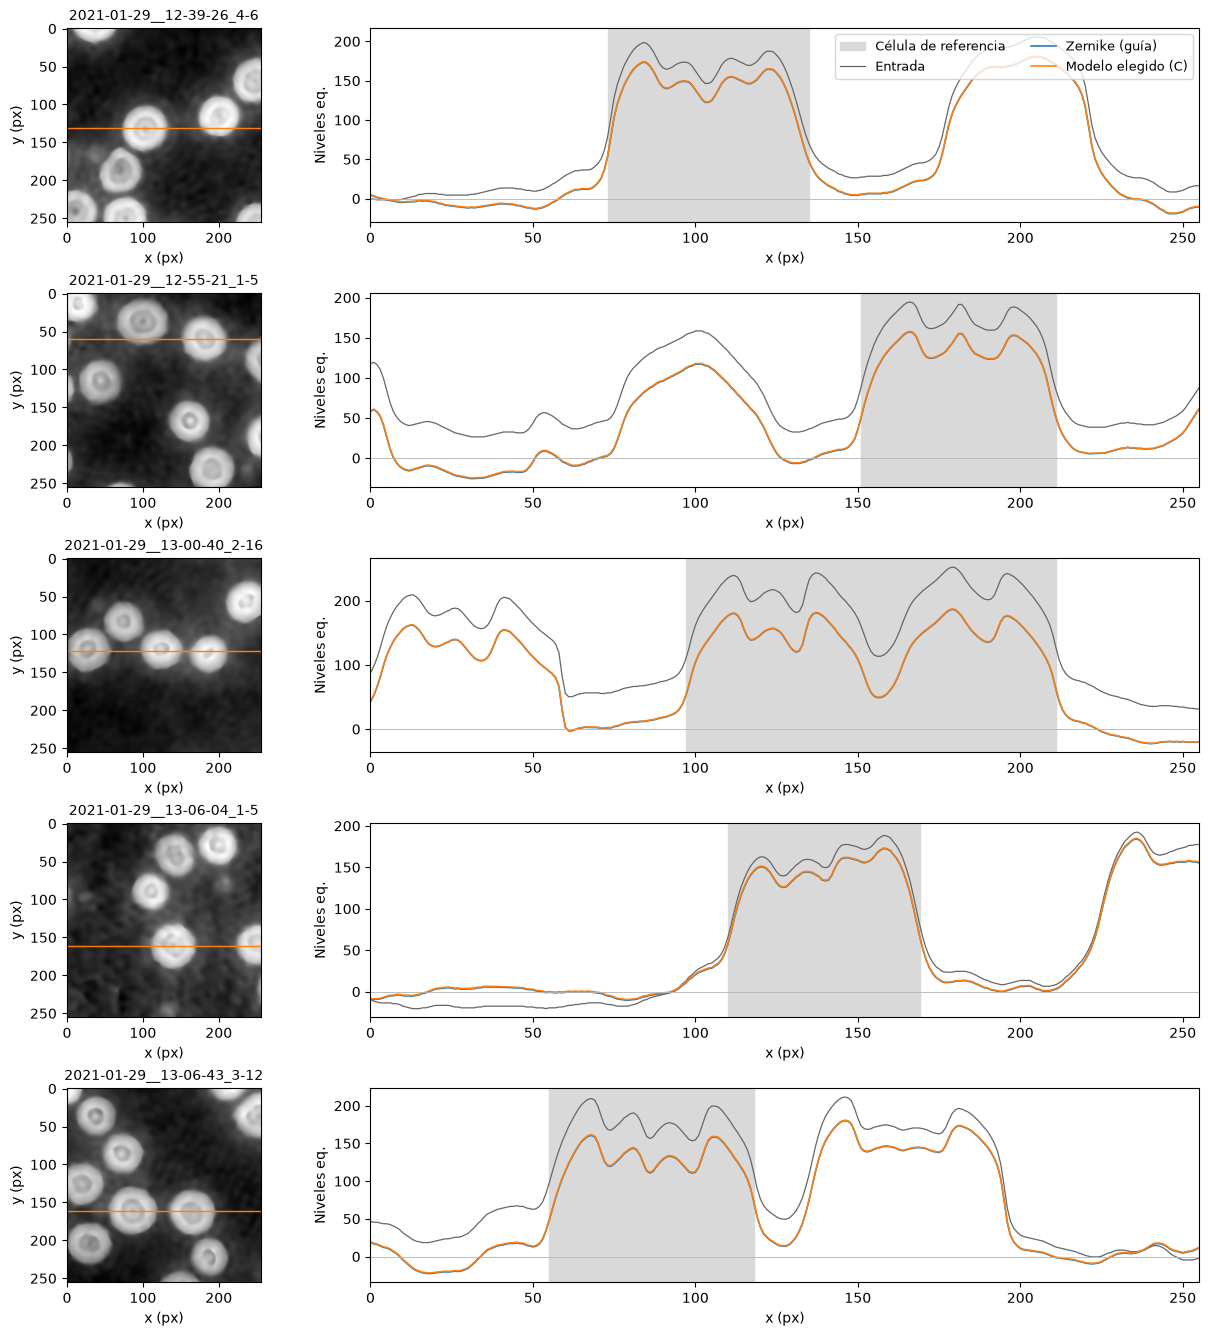

In [17]:
# 9.2 Un perfil por recorte de prueba en los mismos píxeles para todos los métodos
def graficar_perfiles(archivos_perfil):
    fig, axs = plt.subplots(len(archivos_perfil), 2, figsize=(12, 2.65 * len(archivos_perfil)),
                            squeeze=False, width_ratios=[1, 3], layout="constrained")
    for f, (ax_img, ax_perfil) in zip(archivos_perfil, axs):
        u = PREPROCESADAS[f]
        if not CELULAS_EVAL[f]:
            ax_img.set_title(f[7:-4])
            ax_img.imshow(u)
            ax_perfil.text(0.5, 0.5, "Recorte sin célula evaluable", ha="center", va="center",
                           transform=ax_perfil.transAxes)
            ax_perfil.set_axis_off()
            continue
        cel, _ = max(CELULAS_EVAL[f], key=lambda par: par[0].sum())
        fila = int(round(np.nonzero(cel)[0].mean()))
        x = np.arange(u.shape[1])
        ax_img.imshow(u, cmap="gray")
        ax_img.axhline(fila, color="tab:orange", lw=1)
        ax_img.set_title(f[7:-4])
        ax_img.set_xlabel("x (px)")
        ax_img.set_ylabel("y (px)")
        ax_perfil.fill_between(x, 0, 1, where=cel[fila], color="0.85",
                               transform=ax_perfil.get_xaxis_transform(), label="Célula de referencia")
        ax_perfil.plot(x, u[fila], color="0.4", lw=0.9, label="Entrada")
        for metodo, color in [(MEJOR_LB_PRUEBA, "tab:blue"), (NOMBRE_MODELO, "tab:orange")]:
            v = u - FONDOS_PRUEBA[f][metodo]
            ax_perfil.plot(x, v[fila], color=color, lw=1.15, label=metodo)
        ax_perfil.axhline(0, color="0.7", lw=0.6)
        ax_perfil.set_xlim(0, u.shape[1] - 1)
        ax_perfil.set_xlabel("x (px)")
        ax_perfil.set_ylabel("Niveles eq.")
    axs[0, 1].legend(ncol=2, loc="upper right")
    plt.show()
    guardar_figura(fig, "E5", "perfiles_prueba")


graficar_perfiles(PARES_PRUEBA.index.tolist())

### 9.3 Ejemplos visuales y fondo residual

Se muestra un caso intermedio y el caso con mayor M1 del modelo. La entrada y las correcciones comparten la escala de fase dentro de cada recorte. Los mapas de fondo lento usan los píxeles válidos de la métrica M1 y una escala simétrica común por recorte. La visualización negra conserva solo el soporte umbralizado de la fase corregida, usando la estimación de ruido de la imagen de entrada (3.9). El residuo completo alimenta todas las métricas. En los mapas divergentes, las áreas blancas sin datos corresponden a regiones excluidas del cálculo de M1.

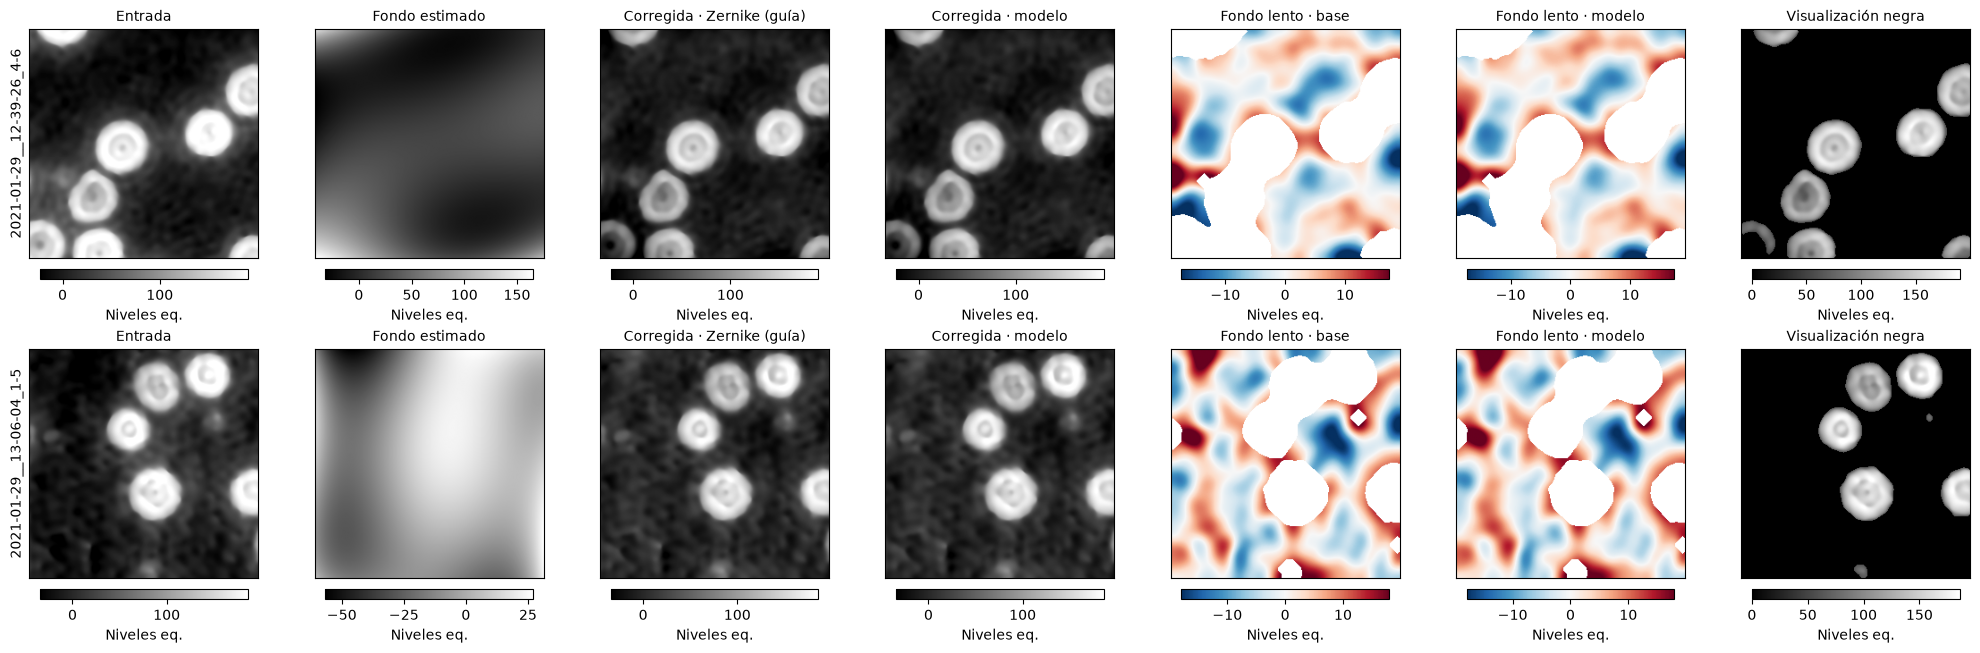

In [18]:
# 9.3 Entrada, fondo estimado, corrección y visualización
def figuras_finales(archivos, fondos, base, etapa, nombre):
    fig, axs = plt.subplots(len(archivos), 7, figsize=(20, 3.2 * len(archivos)),
                            squeeze=False, layout="constrained")
    for f, ejes in zip(archivos, axs):
        u = PREPROCESADAS[f]
        b = fondos[f][NOMBRE_MODELO]
        corregida = u - b
        v_base = u - fondos[f][base]
        residuo_m, _ = fondo_lento(corregida, MASCARAS[f][1])
        residuo_b, _ = fondo_lento(v_base, MASCARAS[f][1])
        visual = np.where(soporte(corregida, SIGMA_RUIDO[f]), np.maximum(corregida, 0), 0)
        lo, hi = np.percentile(np.stack([u, corregida, v_base]), [1, 99])
        rango_residuo = max(float(np.nanpercentile(np.abs([residuo_b, residuo_m]), 98)), 1)
        paneles = [
            (u, "Entrada", "gray", min(lo, 0), hi),
            (b, "Fondo estimado", "gray", None, None),
            (v_base, f"Corregida · {base}", "gray", min(lo, 0), hi),
            (corregida, "Corregida · modelo", "gray", min(lo, 0), hi),
            (residuo_b, "Fondo lento · base", "RdBu_r", -rango_residuo, rango_residuo),
            (residuo_m, "Fondo lento · modelo", "RdBu_r", -rango_residuo, rango_residuo),
            (visual, "Visualización negra", "gray", 0, max(hi, 1)),
        ]
        for ax, (img, titulo, cmap, vmin, vmax) in zip(ejes, paneles):
            im = ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
            ax.set_title(titulo)
            ax.set_xticks([])
            ax.set_yticks([])
            fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.75, pad=0.04, label="Niveles eq.")
        ejes[0].set_ylabel(f[7:-4])
    plt.show()
    guardar_figura(fig, etapa, nombre)


orden_prueba = filas_modelo[L].sort_values().index.tolist()
CASOS_PRUEBA = [orden_prueba[len(orden_prueba) // 2], orden_prueba[-1]]
figuras_finales(CASOS_PRUEBA, FONDOS_PRUEBA, MEJOR_LB_PRUEBA, "E5", "ejemplos_prueba")

### 9.4 Análisis de errores y preservación celular

La línea base elegible de menor RMS lento fue Zernike. Las medianas del modelo y la línea base fueron **6,468 y 6,487 niveles** en M1, y **2,91 % y 2,94 %** en M2. El modelo dejó menos fondo lento en cuatro de cinco recortes y menor cambio de altura en tres. Las dos condiciones mejoraron a la vez en dos recortes. Se evaluaron 12 células en los cinco recortes.

Los perfiles de ambas correcciones casi se superponen. En el recorte `13-06-04_1-5`, el de mayor M1 del modelo, el ajuste aumentó el fondo lento de 7,220 a 7,320 niveles, con cambios de altura próximos al 2,93 %. En el recorte `13-00-40_2-16`, la reducción de M1 fue de 0,042 niveles y M2 quedó cerca del límite, en 4,82 %. Los perfiles muestran cambios locales comparables y el enmascaramiento visual permite ver los eritrocitos sobre fondo negro. La fase corregida conserva variaciones de fondo medibles.


## 10. Generalización con datos no vistos  *(lineamiento D)*

Se aplica la misma configuración congelada a ocho recortes de tres adquisiciones del 28/01, un día excluido del desarrollo. La selección de generalización incluye recortes con fondos más difíciles y células parciales (3.6–3.9 del notebook del equipo). Se informa el desempeño por imagen y se comprueba la sensibilidad a la unidad de resumen mediante medianas de las adquisiciones, para que una adquisición con varios recortes no tenga más peso. Los recortes sin células evaluables aportan a M1 y quedan fuera del resumen de M2.

In [19]:
# 10.1 Evaluación sobre el día excluido del desarrollo
EVAL_GENERAL, FONDOS_GENERAL = evaluar_conjunto_final("generalizacion")
RESUMEN_GENERAL = resumir_final(EVAL_GENERAL)
guardar_evaluacion(EVAL_GENERAL, RESUMEN_GENERAL, "GEN_generalizacion")
display(RESUMEN_GENERAL[[L, ADH, DH, "tiempo (s)"]].round(3))
display(EVAL_GENERAL.pivot(index=["adquisición", "archivo"], columns="método", values=[L, ADH]).round(2))

# Cada adquisición contribuye con una mediana por método, independientemente del número de recortes.
MEDIANAS_POR_ADQ = (
    EVAL_GENERAL.groupby(["adquisición", "método"], as_index=False)
    .agg({L: "median", ADH: "median", "archivo": "size", "células evaluadas": "sum"})
    .rename(columns={"archivo": "recortes"})
)
RESUMEN_POR_ADQ = (
    MEDIANAS_POR_ADQ.groupby("método")[[L, ADH]].agg(["median", "count"])
    .reindex([*METODOS_FINAL, NOMBRE_MODELO])
)
guardar_tabla(MEDIANAS_POR_ADQ, "GEN_por_adquisicion")
display(RESUMEN_POR_ADQ.round(3))

[calculado] 'LB_Image__2021-01-28__15-49-28_4-10' en 2.4 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-28__15-49-28_4-2-A' en 2.2 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-28__15-49-28_4-5-A' en 2.2 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-28__15-49-38_1-1' en 2.2 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-28__15-49-38_2-1-A' en 2.4 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-28__15-49-38_3-1' en 2.4 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-28__16-04-42_1-4-A' en 2.2 s y guardado en results/fourier/cache/


[calculado] 'LB_Image__2021-01-28__16-04-42_2-3-B' en 2.5 s y guardado en results/fourier/cache/


RMS lento (niveles eq.)                   |Δh| mediana (%)  \
                                   mediana   media     DE  n          mediana   
método                                                                          
Pistón                              20.530  20.627  5.839  8            0.000   
Polinomio g3                         9.286  10.110  3.879  8            2.014   
Zernike (guía)                       5.984   6.913  2.381  8            4.604   
SIREN ω0=1 (guía)                    3.810   4.624  2.842  8           12.495   
Modelo elegido (C)                   6.066   6.936  2.417  8            4.594   

                                     Δh mediana (%)                    \
                     media     DE  n        mediana   media     DE  n   
método                                                                  
Pistón               0.000  0.000  7          0.000  -0.000  0.000  7   
Polinomio g3         2.472  1.640  7         -1.410  -2.249  1.809  7   
Zernike (guía)       4.893  2.387  7         -4.604  -4.893  2.387  7   
SIREN ω0=1 (guía)   13.190  3.443  7        -12.495 -13.190  3.443  7   
Modelo elegido (C)   4.909  2.377  7         -4.594  -4.909  2.377  7   

                   tiempo (s)                   
                      mediana  media     DE  n  
método                                          
Pistón                  0.000  0.000  0.000  8  
Polinomio g3            0.036  0.036  0.003  8  
Zernike (guía)          1.290  1.297  0.098  8  
SIREN ω0=1 (guía)       0.922  0.920  0.034  8  
Modelo elegido (C)      1.265  1.301  0.102  8

RMS lento (niveles eq.)  \
método                                                          Modelo elegido (C)   
adquisición          archivo                                                         
2021-01-28__15-49-28 Image__2021-01-28__15-49-28_4-10.png                     4.96   
                     Image__2021-01-28__15-49-28_4-2-A.png                    7.50   
                     Image__2021-01-28__15-49-28_4-5-A.png                    5.37   
2021-01-28__15-49-38 Image__2021-01-28__15-49-38_1-1.png                      5.91   
                     Image__2021-01-28__15-49-38_2-1-A.png                   12.47   
                     Image__2021-01-28__15-49-38_3-1.png                      6.23   
2021-01-28__16-04-42 Image__2021-01-28__16-04-42_1-4-A.png                    7.46   
                     Image__2021-01-28__16-04-42_2-3-B.png                    5.60   

                                                                   \
método                                                     Pistón   
adquisición          archivo                                        
2021-01-28__15-49-28 Image__2021-01-28__15-49-28_4-10.png    9.95   
                     Image__2021-01-28__15-49-28_4-2-A.png  24.59   
                     Image__2021-01-28__15-49-28_4-5-A.png  27.39   
2021-01-28__15-49-38 Image__2021-01-28__15-49-38_1-1.png    17.01   
                     Image__2021-01-28__15-49-38_2-1-A.png  26.69   
                     Image__2021-01-28__15-49-38_3-1.png    18.52   
2021-01-28__16-04-42 Image__2021-01-28__16-04-42_1-4-A.png  22.54   
                     Image__2021-01-28__16-04-42_2-3-B.png  18.33   

                                                                         \
método                                                     Polinomio g3   
adquisición          archivo                                              
2021-01-28__15-49-28 Image__2021-01-28__15-49-28_4-10.png          5.94   
                     Image__2021-01-28__15-49-28_4-2-A.png         9.65   
                     Image__2021-01-28__15-49-28_4-5-A.png         7.08   
2021-01-28__15-49-38 Image__2021-01-28__15-49-38_1-1.png          11.05   
                     Image__2021-01-28__15-49-38_2-1-A.png        15.88   
                     Image__2021-01-28__15-49-38_3-1.png           8.92   
2021-01-28__16-04-42 Image__2021-01-28__16-04-42_1-4-A.png        15.68   
                     Image__2021-01-28__16-04-42_2-3-B.png         6.67   

                                                                              \
método                                                     SIREN ω0=1 (guía)   
adquisición          archivo                                                   
2021-01-28__15-49-28 Image__2021-01-28__15-49-28_4-10.png               3.92   
                     Image__2021-01-28__15-49-28_4-2-A.png              3.29   
                     Image__2021-01-28__15-49-28_4-5-A.png              3.08   
2021-01-28__15-49-38 Image__2021-01-28__15-49-38_1-1.png                3.42   
                     Image__2021-01-28__15-49-38_2-1-A.png             11.61   
                     Image__2021-01-28__15-49-38_3-1.png                4.07   
2021-01-28__16-04-42 Image__2021-01-28__16-04-42_1-4-A.png              3.90   
                     Image__2021-01-28__16-04-42_2-3-B.png              3.72   

                                                                           \
método                                                     Zernike (guía)   
adquisición          archivo                                                
2021-01-28__15-49-28 Image__2021-01-28__15-49-28_4-10.png            4.93   
                     Image__2021-01-28__15-49-28_4-2-A.png           7.48   
                     Image__2021-01-28__15-49-28_4-5-A.png           5.36   
2021-01-28__15-49-38 Image__2021-01-28__15-49-38_1-1.png             5.77   
                     Image__2021-01-28__15-49-38_2-1-A.png          12.34   
                     Image__2

RMS lento (niveles eq.)       |Δh| mediana (%)      
                                    median count           median count
método                                                                 
Pistón                              20.437     3            0.000     3
Polinomio g3                        11.051     3            2.559     3
Zernike (guía)                       6.201     3            3.870     3
SIREN ω0=1 (guía)                    3.810     3           13.600     3
Modelo elegido (C)                   6.226     3            3.899     3

,dominio,método,recortes,adquisiciones,recortes con M2,RMS lento (niveles eq.),|Δh| mediana (%),Δh mediana (%)
0,Prueba,Pistón,5,5,5,18.184,0.000,0.000
1,Prueba,Polinomio g3,5,5,5,10.367,1.187,-0.826
2,Prueba,Zernike (guía),5,5,5,6.487,2.939,-2.939
3,Prueba,SIREN ω0=1 (guía),5,5,5,4.237,12.325,-12.325
4,Prueba,Modelo elegido (C),5,5,5,6.468,2.914,-2.914
5,Generalización,Pistón,8,3,7,20.530,0.000,0.000
6,Generalización,Polinomio g3,8,3,7,9.286,2.014,-1.410
7,Generalización,Zernike (guía),8,3,7,5.984,4.604,-4.604
8,Generalización,SIREN ω0=1 (guía),8,3,7,3.810,12.495,-12.495
9,Generalización,Modelo elegido (C),8,3,7,6.066,4.594,-4.594


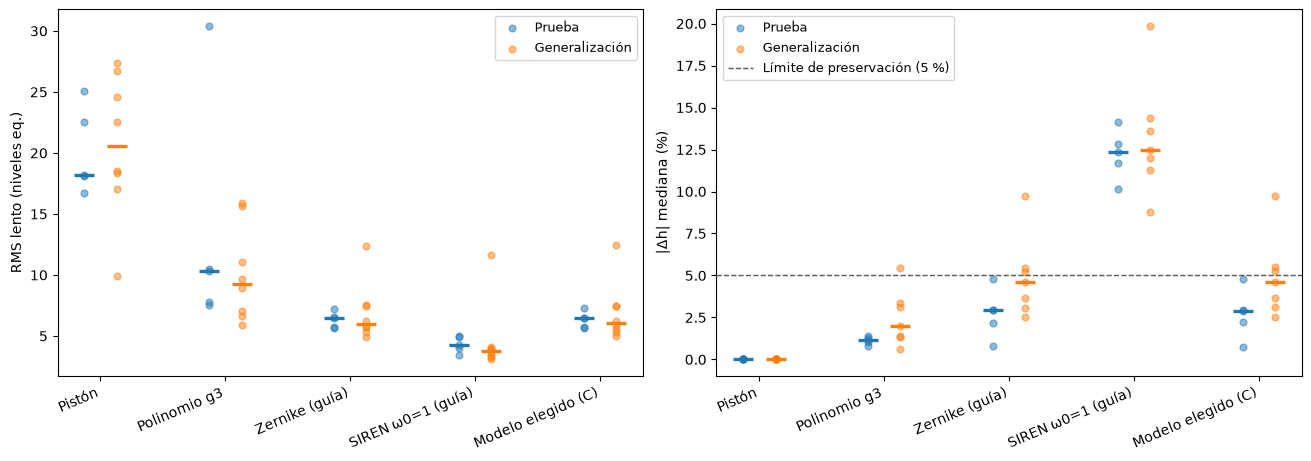

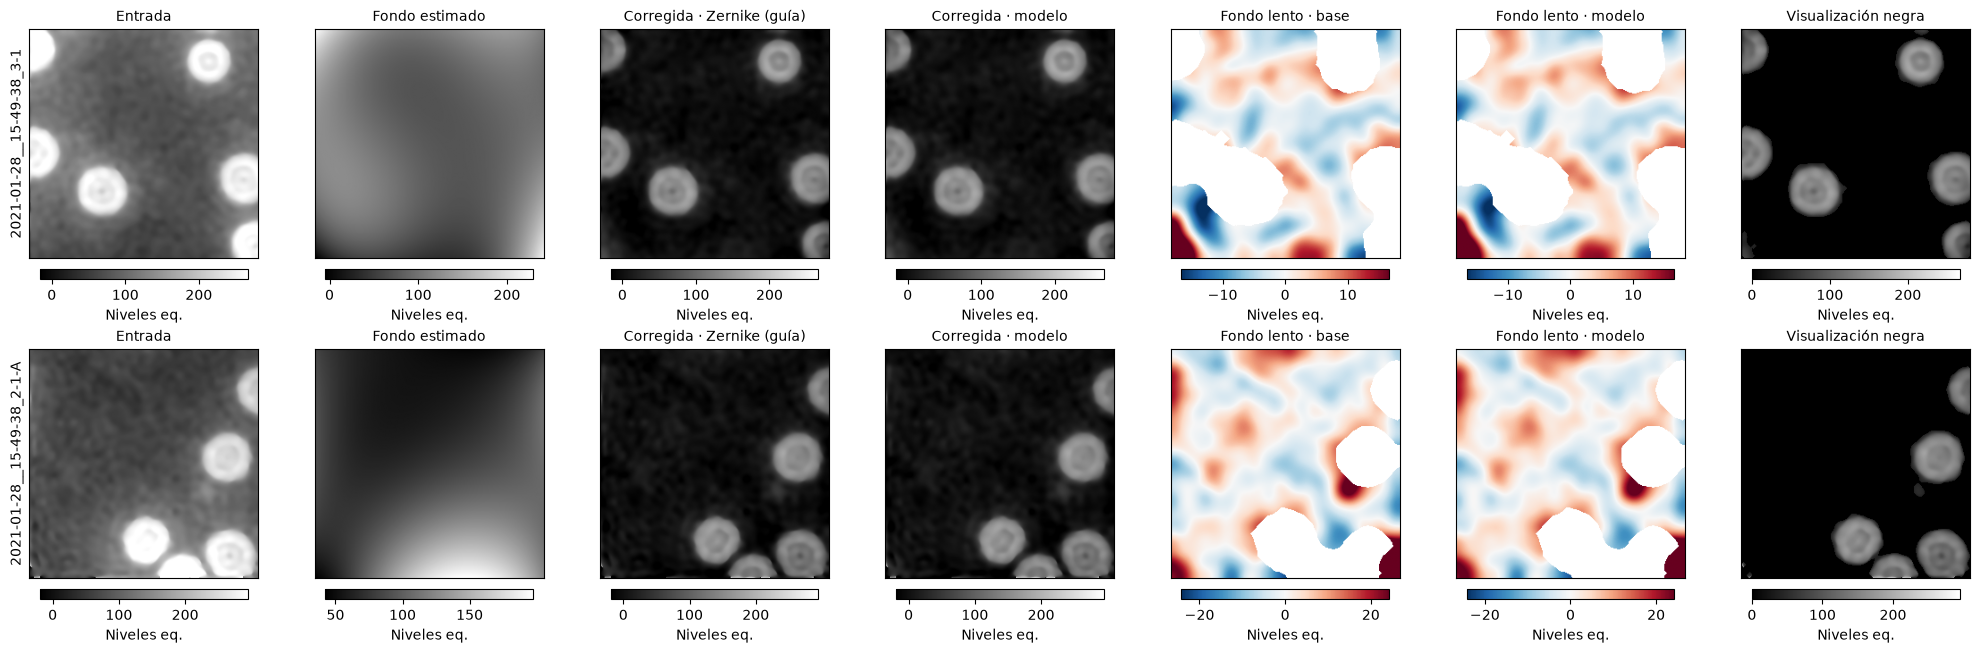

In [20]:
# 10.2 Comparación prueba frente a generalización y ejemplos
filas_dominio = []
for dominio, tabla in [("Prueba", EVAL_PRUEBA), ("Generalización", EVAL_GENERAL)]:
    for metodo, grupo in tabla.groupby("método", sort=False):
        filas_dominio.append({
            "dominio": dominio, "método": metodo, "recortes": len(grupo),
            "adquisiciones": grupo["adquisición"].nunique(), "recortes con M2": grupo[ADH].count(),
            L: grupo[L].median(), ADH: grupo[ADH].median(), DH: grupo[DH].median(),
        })
COMPARACION_DOMINIO = pd.DataFrame(filas_dominio)
guardar_tabla(COMPARACION_DOMINIO, "GEN_comparacion_dominios")
display(COMPARACION_DOMINIO.round(3))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
metodos_grafica = [*METODOS_FINAL, NOMBRE_MODELO]
for ax, metrica in zip(axs, [L, ADH]):
    for dominio, tabla, color, desplazamiento in [
        ("Prueba", EVAL_PRUEBA, "tab:blue", -0.13),
        ("Generalización", EVAL_GENERAL, "tab:orange", 0.13),
    ]:
        for i, metodo in enumerate(metodos_grafica):
            valores = tabla.loc[tabla["método"] == metodo, metrica].dropna()
            ax.scatter(np.full(len(valores), i + desplazamiento), valores, color=color, alpha=0.5,
                       s=24, label=dominio if i == 0 else None)
            ax.scatter(i + desplazamiento, valores.median(), color=color, marker="_", linewidths=2.4, s=220)
    if metrica == ADH:
        ax.axhline(5, color="0.35", ls="--", lw=1, label="Límite de preservación (5 %)")
    ax.set_xticks(range(len(metodos_grafica)), metodos_grafica, rotation=23, ha="right")
    ax.set_ylabel(metrica)
    ax.legend()
plt.show()
guardar_figura(fig, "GEN", "comparacion_dominios")

orden_gen = EVAL_GENERAL[EVAL_GENERAL["método"] == NOMBRE_MODELO].sort_values(L).archivo.tolist()
CASOS_GENERAL = [orden_gen[len(orden_gen) // 2], orden_gen[-1]]
figuras_finales(CASOS_GENERAL, FONDOS_GENERAL, MEJOR_LB_PRUEBA, "GEN", "ejemplos_generalizacion")

### 10.3 Lectura de la generalización

El modelo obtuvo un RMS lento mediano de **6,066 niveles** frente a **5,984** de Zernike. La altura cambió **4,59 %** frente a **4,60 %**. Al dar el mismo peso a las tres adquisiciones, el RMS quedó en **6,226 frente a 6,201** niveles, y el cambio de altura en **3,90 % frente a 3,87 %**. La comparación de fondo sigue favoreciendo ligeramente a Zernike bajo ambas formas de resumen.

Tres de los siete recortes con células evaluables rebasaron el 5 %. El recorte `15-49-38_3-1` llegó al **9,70 %** en una sola célula evaluable. El recorte `15-49-38_2-1-A` presentó el mayor RMS lento (**12,47 niveles**) y quedó fuera de M2 por la falta de una célula que cumpliera los criterios de área, borde y anillo de la sección 6. El conjunto reservado tiene menor fracción celular mediana y más saltos de fondo que prueba (3.7 del notebook del equipo). Esas diferencias de composición y calidad pueden contribuir a la dispersión observada. En la figura, cada punto es un recorte y la raya del mismo color marca la mediana.


## 11. Discusión

La comparación en prueba identifica tres opciones con costos y compromisos distintos. El polinomio de grado 3 obtuvo **10,37 niveles** de fondo lento, **1,19 %** de cambio de altura y una mediana de **0,042 s** por imagen. La SIREN guía obtuvo **4,24 niveles** y **12,33 %** de cambio de altura, por encima del límite de preservación. Zernike y la red condicional quedaron entre esos dos comportamientos, con tiempos medianos de **1,48 y 1,43 s**, respectivamente. Los 15 coeficientes de Zernike se ajustan para cada imagen. La red comparte sus 41.261 parámetros entrenados y sigue calculando Zernike para cada entrada.

La corrección de Fourier se limita a frecuencias bajas y es periódica en bordes opuestos. Además, los pesos de ajuste dependen del residuo que dejó Zernike. Una región elevada por aberración puede recibir poco peso si parece una célula. Ambas decisiones pueden limitar cuánto corrige la red en casos difíciles. El experimento mide el aporte del sistema completo frente a Zernike. Queda abierta la contribución específica de la CNN frente a un ajuste robusto directo de los mismos coeficientes.

El umbral del 5 % corresponde al cambio de altura local definido para este proyecto. La fase celular aislada sigue siendo desconocida y las máscaras se derivan de la fase medida. Con cinco adquisiciones de prueba y tres del día reservado, los resultados tienen alcance descriptivo. La diferencia de 0,019 niveles en prueba es pequeña frente a la variación entre recortes y cambió de dirección en el otro día.


## 12. Conclusiones *(lineamiento E)*

La selección por adquisición evita evaluar sobre recortes aumentados de escenas ya usadas para el desarrollo. Con esa partición, la parametrización de Fourier permitió entrenar una corrección suave y conservar la altura celular mediana dentro del límite en ambos días. El margen de fondo en prueba fue estrecho y la comparación del segundo día favoreció a Zernike.

| Objetivo | Evidencia | Alcance logrado |
|---|---|---|
| General | 7–10 | Se entrenó y evaluó una red informada por el modelo aditivo, con visualizaciones de fondo negro y preservación medida en los perfiles. La ventaja frente a Zernike dependió del conjunto. |
| Específico 1 | 4 y 7–8 | Se implementaron una SIREN y un modelo condicional de Fourier, se compararon con una CNN y se evaluó una ablación de la pérdida. |
| Específico 2 | 3 del notebook del equipo | Se conserva la selección congelada de 30 recortes en cuatro conjuntos. |
| Específico 3 | 6 y 9–10 | Se usan las métricas verificadas con valores conocidos en el notebook del equipo y se compararon fondo, altura y perfiles sobre adquisiciones reservadas. |

La evaluación queda limitada por la cantidad de adquisiciones, el formato PNG sin calibración explícita y la referencia operativa de altura. Una extensión directa sería ampliar la muestra de días y adquisiciones y medir la recuperación con simulaciones que conozcan por separado el fondo y la fase de cada célula. Un ajuste no neuronal sobre la misma base de Fourier permitiría medir cuánto aporta aprender los coeficientes entre imágenes.


## 13. Referencias

1. R. Castaneda, C. Trujillo y A. Doblas (2024). A human erythrocytes hologram dataset for learning-based model training. *Data in Brief*, 54, 110424. [Artículo](https://doi.org/10.1016/j.dib.2024.110424) · [Datos](https://doi.org/10.17605/OSF.IO/8P7BA).
2. D. Xu, L. Cao y H. Sun (2025). Adaptive aberration-corrected quantitative phase microscopy via physics-informed deep learning. *Advanced Photonics*, 7(6), 066013. [Artículo](https://doi.org/10.1117/1.AP.7.6.066013) · [Código de PICNet](https://github.com/THUHoloLab/PICNet).
3. J. Tang, J. Zhang, S. Zhang, S. Mao, Z. Ren, J. Di y J. Zhao (2023). Phase aberration compensation via a self-supervised sparse constraint network in digital holographic microscopy. *Optics and Lasers in Engineering*, 168, 107671. [Artículo](https://doi.org/10.1016/j.optlaseng.2023.107671).
4. Z. Huang y L. Cao (2023). Phase aberration separation for holographic microscopy by alternating direction sparse optimization. *Optics Express*, 31(8), 12520–12533. [Artículo](https://doi.org/10.1364/OE.488201).
5. V. Sitzmann, J. N. P. Martel, A. W. Bergman, D. B. Lindell y G. Wetzstein (2020). Implicit Neural Representations with Periodic Activation Functions. *Advances in Neural Information Processing Systems*, 33. [Artículo](https://proceedings.neurips.cc/paper_files/paper/2020/hash/53c04118df112c13a8c34b38343b9c10-Abstract.html) · [arXiv:2006.09661](https://arxiv.org/abs/2006.09661).
6. M. Tancik, P. P. Srinivasan, B. Mildenhall, S. Fridovich-Keil, N. Raghavan, U. Singhal, R. Ramamoorthi, J. T. Barron y R. Ng (2020). Fourier Features Let Networks Learn High Frequency Functions in Low Dimensional Domains. *Advances in Neural Information Processing Systems*, 33. [Artículo](https://proceedings.neurips.cc/paper/2020/hash/55053683268957697aa39fba6f231c68-Abstract.html) · [arXiv:2006.10739](https://arxiv.org/abs/2006.10739).
7. M. A. Herráez, D. R. Burton, M. J. Lalor y M. A. Gdeisat (2002). Fast two-dimensional phase-unwrapping algorithm based on sorting by reliability following a noncontinuous path. *Applied Optics*, 41(35), 7437–7444. [Artículo](https://doi.org/10.1364/AO.41.007437).
8. Código guía del curso (sección 4.4). [Copia incluida en el repositorio](../reference_code/INR).